# x50 データの学習とテスト予測（目的変数の種類ごとの個別モデル、LightGBM / XGBoost）

- **作成者**: ImoZukushi
- **作成日**: 2026-10-21（2026-10-25 long 型の入力に変更、欠損に対応）
- **目的**: `notebook/003_feature_engineering_x50.ipynb` が出力した前処理済みの long 型のデータで、目的変数の種類
  （`Y_cat` = Y1〜Y10）ごとに LightGBM または XGBoost のモデルを学習し、テスト期間（2025年）を再帰予測する。
  学習結果・テスト結果・SHAP によるモデル解釈を図で確認する。評価指標は MAE。
- **入力**（long 型。1行 = 日付 × 種類）: `data/processed/x50/x50_train_features.csv`（列 `date`, `Y_cat`, `Y`, `Y_raw`,
  `Y_lag_*`, 日付の特徴量, 説明変数）, `data/processed/x50/x50_test_features.csv`（目的変数なし）
  （評価用に `data/synthetic/x50/dummy_x50_test_answer.csv`。列 `date`, `Y_cat`, `Y`）
- **出力**
  - 種類ごと: `outputs/experiments/x50_{モデル名}_{種類}/{実行日時}/`（予測・スコア・図・SHAP）
  - 全体の要約: `outputs/experiments/x50_{モデル名}_summary/{実行日時}/`（MAE の表・図・ログ）
  - MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **欠損**: 目的変数・説明変数に、散発的な欠損と連続した欠損がある（学習・テストの両方）。欠損は埋めず、目的変数が欠損の行は学習・評価から除く（「リークを防ぐための決まり」の「欠損」）
- **スクリプト版**: `scripts/train_predict_x50.py`（同じ処理を CLI で実行できる）。このノートブックは `scripts/` を
  import せず、同じ関数をノートブック内（「関数の定義」）で定義している

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 前処理 | 説明変数・日付の前処理は、003 で学習データだけを使って fit 済み。ここでは何も fit しない | 003 のリークの確認 |
| 入力 | テストデータに、目的変数（`Y`・`Y_raw`）も、その特徴量（`Y_lag_*`）も無いこと | 1. 読み込み（`load_inputs`） |
| 種類ごとのモデル | Yk のモデルは `Y_cat` = Yk の行だけで学習し、特徴量は「自身のラグ等 + 日付 + 説明変数」だけ。他の種類の値は使わない（テスト期間では分からないため） | 2. 学習（`prepare`） |
| 目的変数の特徴量 | ラグ・移動平均・前日比は、学習時は過去の実測値から、検証・テスト期間は**再帰予測の中で予測値から**作り直す。学習データのCSVの値と一致すること（＝CSVの値も過去の値だけから作られている）を確かめる | 2. 学習（`prepare`） |
| CV | 日付で区切る時系列CV。各 fold は境目より前だけで学習し、境目以降を**実測値を使わずに**再帰予測して評価する（本番のテスト予測と同じ条件） | 2. の fold の期間の確認 |
| 早期終了 | early stopping に使う検証データは各 fold の検証期間だけ。テスト期間のモデルは、学習データ全体で fold の平均の木の本数で学習し直す | `modeling.trainer` / `modeling.forecasting` |
| 評価 | テストの正解ファイルは、テスト予測が終わった後の MAE の計算にだけ使う | `evaluate_test` |
| 欠損 | 欠損は前後の値で埋めない（補間はその日より後の値を使うため）。目的変数が欠損の行は、学習（目的変数として）・評価から除き、ラグの元としては欠損のまま残す。移動平均は窓内の観測値だけで平均する（`ROLLING_MIN_PERIODS`。003 と違う値なら `prepare` でエラー）。説明変数・ラグの欠損はモデルに任せる | 2. 学習（`prepare`）/ `modeling.forecasting` / `modeling.metrics` |

In [1]:
import datetime as dt
import hashlib
import logging
import re
import shutil
import sys
import time
import warnings
from collections.abc import Sequence
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from modeling.config import ExperimentConfig  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.experiment import ExperimentResult, prepare_dataset, run_experiment  # noqa: E402
from modeling.forecasting import ForecastCVResult, make_builder  # noqa: E402
from modeling.metrics import get_metric  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from util.csv_io import read_csv_auto  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

pd.set_option("display.max_columns", 20)

## パラメータ

papermill で実行するときは `-p 名前 値` で上書きできる（このセルに `parameters` タグを付けている）。
リストや真偽値は `-y` で YAML として渡す。

```bash
uv run papermill notebook/004_train_predict_x50.ipynb out.ipynb --cwd notebook \
    -y "{MODEL: xgboost, TARGET_CATS: [Y1, Y2], DETAIL_TARGET: Y2}"
```

In [2]:
MODEL = "lightgbm"  # "lightgbm" または "xgboost"
TARGET_CATS = None  # 予測する目的変数の種類（Y_cat の値。None なら学習データの全種類 Y1〜Y10）
DETAIL_TARGET = "Y1"  # 詳しい図（学習の推移・残差・SHAP など）を表示する種類
N_TRIALS = 0  # 種類ごとの Optuna の試行回数（0 ならチューニングしない）
CUTOFFS = ["2023-07-01", "2024-01-01"]  # 時系列CVの検証期間の開始日
TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
USE_TRACKING = True  # MLflow に記録するか
USE_ANSWER = True  # テストの正解ファイルで MAE を計算するか
OUTPUT_ROOT = None  # 出力のルート（None なら outputs/experiments）

## 関数の定義

このノートブックは `scripts/` のモジュールを import せず、使う関数をここで定義する。CLI で同じ処理を行う
`scripts/train_predict_x50.py` にも同じ関数があり、内容は同じ（どちらかを変えるときは、もう一方も揃える）。
関数の中では `src/` のモジュール（`modeling`・`util`）を使う。

### 定数と結果の入れ物

入出力のパス・列名（日付 `date`・種類 `Y_cat`・目的変数 `Y`）・CVの境目の既定値と、リークのおそれを表すエラー
（`LeakageError`）、読み込んだ入力（`Inputs`）・種類ごとの結果（`TargetRun`）をまとめるクラス。

In [3]:
MODELS = ("lightgbm", "xgboost")


TRAIN_PATH = data_dir() / "processed" / "x50" / "x50_train_features.csv"


TEST_PATH = data_dir() / "processed" / "x50" / "x50_test_features.csv"


ANSWER_PATH = data_dir() / "synthetic" / "x50" / "dummy_x50_test_answer.csv"


DATE_COL = "date"


CAT_COL = "Y_cat"  # 目的変数の種類（Y1〜Y10）の列


TARGET_COL = "Y"  # 目的変数の値の列（学習データのCSVでは対数。モデルに渡す表では元の尺度にする）


RAW_SUFFIX = "_raw"  # 学習データのCSVの、元の尺度の目的変数の列名の接尾辞（`Y_raw`）


PRED_COL = "pred"  # 種類ごとのテスト予測の表の、予測値の列


ACTUAL_COL = "actual"  # 同じく、正解の列（正解ファイルがある場合）


# 移動平均に必要な、窓内の観測値（欠損でない値）の最小数。003 の前処理と同じ値にする
# （違えば `prepare` で「CSVの値と一致しない」エラーになる）
ROLLING_MIN_PERIODS = 1


# 検証期間の開始日（時系列CVの各foldの境目）。最後の fold は学習データの最終日まで
DEFAULT_CUTOFFS = ["2023-07-01", "2024-01-01"]


MLFLOW_EXPERIMENT = "x50_forecast"


logger = logging.getLogger("train_predict_x50")


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


@dataclass(frozen=True)
class TargetFeatureSpec:
    """学習データのCSVにある、目的変数から作った特徴量の定義（列名から読み取る）。

    特徴量は種類（`Y_cat`）ごとに作られているが、列名・定義は全種類で共通。

    Attributes:
        target: 目的変数の列名（`Y`）。
        lags: ラグ（`{target}_lag_{k}`）。
        rolling_windows: 前日までの移動平均の窓幅（`{target}_lag_1_ma_{w}`）。
        rate_of_change: 前日の前日比（`{target}_lag_1_roc_1`）があるか。
        columns: これらの列名（CSVの並び順）。
    """

    target: str
    lags: list[int]
    rolling_windows: list[int]
    rate_of_change: bool
    columns: list[str] = field(default_factory=list)


@dataclass
class Inputs:
    """読み込んで確認した入力（いずれも long 型）。

    Attributes:
        train: 学習データのCSV（選んだ種類の行だけ。日付の昇順、同じ日付の中は種類の順）。
        test: テストデータのCSV（同上）。
        categories: 予測する目的変数の種類（`Y_cat` の値。データに出てくる順）。
        spec: 目的変数の特徴量の定義（全種類で共通）。
        exog_cols: 日付の特徴量・説明変数の列（学習・テストで共通。全種類のモデルで使う）。
    """

    train: pd.DataFrame
    test: pd.DataFrame
    categories: list[str]
    spec: TargetFeatureSpec
    exog_cols: list[str]


@dataclass
class TargetRun:
    """1つの種類（`Y_cat` の値）の学習・予測の結果。

    Attributes:
        category: 目的変数の種類（例: `Y1`）。
        dataset: 学習用データ一式。
        result: `run_experiment` の結果。
        predictions: テスト予測（列 `date`, `pred`。正解があれば `actual` も）。
        test_mae: テストの MAE（正解が無ければNone）。
    """

    category: str
    dataset: Dataset
    result: ExperimentResult
    predictions: pd.DataFrame
    test_mae: float | None

### ログ

画面とファイルの両方にログを出す設定（`setup_logging`）、ログに出すパスをリポジトリからの相対パスにする関数（`shown`）、
入力ファイルのハッシュ（どのデータで学習したかの記録用）。

In [4]:
def setup_logging(log_path: Path, level: int = logging.INFO) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    root = logging.getLogger()
    root.setLevel(level)
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    handlers: list[logging.Handler] = [
        logging.FileHandler(log_path, encoding="utf-8"),
        logging.StreamHandler(sys.stdout),
    ]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

### 読み込みとリークの確認

long 型の学習データの列から、目的変数の特徴量の定義（ラグ・移動平均・前日比）を読み取り、テストデータに目的変数
（`Y`・`Y_raw`）やその特徴量（`Y_lag_*`）が無いこと・学習とテストで特徴量の列が同じこと・種類ごとに日付が1日刻みで
続いていることを確かめる（`load_inputs`）。行は日付の昇順、同じ日付の中は種類の順に並べる（`sort_long`）。

`model_frames` は、1つの種類について `prepare_dataset` に渡す表を作る（その種類の行だけを取り出し、種類の列と
CSVにある目的変数の特徴量は外す）。

In [5]:
def category_order(frame: pd.DataFrame) -> list[str]:
    """目的変数の種類（`Y_cat` の値）を、データに出てくる順に返す。"""
    return [str(c) for c in dict.fromkeys(frame[CAT_COL])]


def sort_long(frame: pd.DataFrame, categories: Sequence[str]) -> pd.DataFrame:
    """long 型の表を、日付の昇順・同じ日付の中は種類の順（categories の順）に並べる。"""
    order = {cat: i for i, cat in enumerate(categories)}
    return frame.sort_values(
        [DATE_COL, CAT_COL],
        key=lambda s: s.map(order) if s.name == CAT_COL else s,
        kind="stable",
    ).reset_index(drop=True)


def parse_target_features(columns: Sequence[str], target: str = TARGET_COL) -> TargetFeatureSpec:
    """列名から、目的変数のラグ・移動平均・前日比の定義を読み取る。

    Raises:
        ValueError: 再帰予測で作り直せない目的変数の特徴量がある場合
            （2日以上前のラグの移動平均など）、またはラグが無い場合。
    """
    lags, windows, roc, found = [], [], False, []
    prefix = f"{target}_lag_"
    for col in columns:
        if not col.startswith(prefix):
            continue
        found.append(col)
        if m := re.fullmatch(rf"{re.escape(prefix)}(\d+)", col):
            lags.append(int(m.group(1)))
        elif m := re.fullmatch(rf"{re.escape(prefix)}1_ma_(\d+)", col):
            windows.append(int(m.group(1)))
        elif col == f"{prefix}1_roc_1":
            roc = True
        else:
            raise ValueError(f"再帰予測で作り直せない目的変数の特徴量です: {col}")
    if not lags:
        raise ValueError(f"学習データに目的変数のラグ（{prefix}k）がありません")
    return TargetFeatureSpec(target, sorted(lags), sorted(windows), roc, found)


def check_daily(frame: pd.DataFrame, name: str) -> None:
    """種類ごとに、日付が1日刻みで重複も欠けもないことを確かめる（ラグは1行=1日の前提で作るため）。"""
    for category, part in frame.groupby(CAT_COL, sort=False):
        gaps = part[DATE_COL].diff().dropna()
        if part[DATE_COL].duplicated().any() or not (gaps == pd.Timedelta(days=1)).all():
            raise ValueError(
                f"{name}（{category}）の日付が1日刻みになっていません（重複または欠け）"
            )


def load_inputs(
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
    categories: Sequence[str] | None = None,
) -> Inputs:
    """前処理済みの学習・テストデータ（long 型）を読み込み、リークのおそれがないことを確かめる。

    確かめること:
        - テストデータに、目的変数（`Y`・`Y_raw`）も、目的変数から作った特徴量（`Y_lag_*`）も無い。
        - 学習・テストで、日付の特徴量・説明変数の列が同じ。予測する種類が両方にある。
        - 種類ごとに1日刻みで、テストデータは学習データの最終日の翌日から始まる。

    Args:
        train_path: 学習データのCSV。
        test_path: テストデータのCSV。
        categories: 予測する種類（Noneなら学習データの全種類）。

    Raises:
        LeakageError: テストデータに目的変数（またはその特徴量）がある場合。
        ValueError: 列や日付が前提を満たさない場合。
    """
    train = read_csv_auto(train_path)
    test = read_csv_auto(test_path)
    for name, path, frame in (("学習", train_path, train), ("テスト", test_path, test)):
        logger.info(
            "%sデータ: %s（%d行 × %d列, sha256=%s）",
            name,
            path.name,
            *frame.shape,
            file_digest(path),
        )

    raw_col = f"{TARGET_COL}{RAW_SUFFIX}"
    for name, frame, required in (
        ("学習", train, [DATE_COL, CAT_COL, TARGET_COL, raw_col]),
        ("テスト", test, [DATE_COL, CAT_COL]),
    ):
        missing = [c for c in required if c not in frame.columns]
        if missing:
            raise ValueError(f"{name}データに列がありません: {missing}")
    # 種類の列（Y_cat）は目的変数の値ではないので除く
    leaked = [
        c
        for c in test.columns
        if c != CAT_COL and (c in (TARGET_COL, raw_col) or c.startswith(f"{TARGET_COL}_"))
    ]
    if leaked:
        raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")

    all_categories = category_order(train)
    selected = list(categories) if categories else all_categories
    unknown = [c for c in selected if c not in all_categories]
    if unknown:
        raise ValueError(f"学習データに無い種類です: {unknown}（あるのは {all_categories}）")
    missing_in_test = [c for c in selected if c not in set(test[CAT_COL])]
    if missing_in_test:
        raise ValueError(f"テストデータに無い種類です: {missing_in_test}")

    columns = list(train.columns)
    spec = parse_target_features(columns)
    target_cols = {TARGET_COL, raw_col, *spec.columns}
    exog_cols = [c for c in columns if c not in (DATE_COL, CAT_COL) and c not in target_cols]
    if set(exog_cols) != set(test.columns) - {DATE_COL, CAT_COL}:
        only_train = sorted(set(exog_cols) - set(test.columns))
        only_test = sorted(set(test.columns) - set(exog_cols) - {DATE_COL, CAT_COL})
        raise ValueError(
            f"学習・テストで特徴量の列が違います（学習のみ: {only_train}, テストのみ: {only_test}）"
        )

    train = sort_long(train[train[CAT_COL].isin(selected)], selected)
    test = sort_long(test[test[CAT_COL].isin(selected)], selected)
    check_daily(train, "学習データ")
    check_daily(test, "テストデータ")
    train_end = train.groupby(CAT_COL)[DATE_COL].max()
    test_start = test.groupby(CAT_COL)[DATE_COL].min()
    not_next = [c for c in selected if test_start[c] != train_end[c] + pd.Timedelta(days=1)]
    if not_next:
        raise ValueError(
            f"テストデータが学習データの翌日から始まっていない種類があります: {not_next}"
        )
    logger.info(
        "期間: 学習 %s〜%s / テスト %s〜%s",
        f"{train[DATE_COL].min():%Y-%m-%d}",
        f"{train[DATE_COL].max():%Y-%m-%d}",
        f"{test[DATE_COL].min():%Y-%m-%d}",
        f"{test[DATE_COL].max():%Y-%m-%d}",
    )
    logger.info("目的変数の種類（%s）: %s", CAT_COL, selected)
    logger.info(
        "特徴量: 自身のラグ等 %d列（ラグ %s, 移動平均 %s, 前日比 %s。"
        "種類ごとに再帰予測で作り直す）,"
        " 日付・説明変数 %d列",
        len(spec.columns),
        spec.lags,
        spec.rolling_windows,
        spec.rate_of_change,
        len(exog_cols),
    )
    return Inputs(
        train=train,
        test=test[[DATE_COL, CAT_COL, *exog_cols]],
        categories=selected,
        spec=spec,
        exog_cols=exog_cols,
    )


def model_frames(inputs: Inputs, category: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """1つの種類について、`prepare_dataset` に渡す学習・テストの表を作る。

    その種類の行だけを取り出し、学習の表は「日付・日付の特徴量・説明変数・目的変数（元の尺度）」だけにする。
    種類の列と、CSVにある目的変数の特徴量は外す（目的変数の特徴量は `modeling` に同じ定義で
    作り直させる。
    テスト期間は再帰予測の中で作るため）。
    """
    train_rows = inputs.train[inputs.train[CAT_COL] == category]
    train = train_rows[[DATE_COL, *inputs.exog_cols]].assign(
        **{TARGET_COL: train_rows[f"{TARGET_COL}{RAW_SUFFIX}"]}
    )
    test = inputs.test.loc[inputs.test[CAT_COL] == category, [DATE_COL, *inputs.exog_cols]]
    assert TARGET_COL not in test.columns
    return train.reset_index(drop=True), test.reset_index(drop=True)

### 実験設定

1つの種類・1モデル分の `modeling.config.ExperimentConfig` を作る。日付で区切る時系列CV（`time_cutoff`）、
目的変数の対数変換、再帰予測の特徴量の定義（学習データのCSVと同じもの）、SHAP・誤差評価・MLflow の設定を含む。

In [6]:
def make_config(
    model: str,
    spec: TargetFeatureSpec,
    category: str,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
) -> ExperimentConfig:
    """1つの種類・1モデル分の実験設定を作る（`ExperimentConfig` で検証する）。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        spec: 目的変数とその特徴量の定義（学習データのCSVと同じものを再帰予測でも作る）。
        category: 目的変数の種類（実験名に使う）。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方（`refit_full` は学習データ全体で学習し直したモデル、
            `fold_mean` は各foldのモデルの平均）。
        train_path: 記録用の学習データのパス。
        test_path: 記録用のテストデータのパス。

    Returns:
        検証済みの実験設定。

    Raises:
        ValueError: 未対応のモデル名の場合。
    """
    if model not in MODELS:
        raise ValueError(f"モデルは {MODELS} から選んでください: {model}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_{model}_{category}",
            # time_series では時間順を無視したCV（kfold 等）は設定エラーになる
            "task": "time_series",
            "data": {
                "train_path": str(train_path),
                "test_path": str(test_path),
                "target": spec.target,
                # 時刻列。学習データはこの列の昇順に並べ替えられる。モデルの特徴量からは外す
                "time_col": DATE_COL,
                "drop_cols": [DATE_COL],
            },
            # 特徴量の前処理は 003 のノートブックで学習データだけを使って済ませているため、
            # ここでは行わない
            "features": [],
            # 日付で区切る時系列CV。各 fold は「境目より前で学習し、境目以降を再帰予測して評価」する
            "cv": {"method": "time_cutoff", "time_column": DATE_COL, "cutoffs": list(cutoffs)},
            "model": {"name": model, "params": {"n_estimators": 1000}, "early_stopping_rounds": 50},
            "metrics": ["mae"],
            "test_prediction": test_prediction,
            "forecast": {
                "lags": spec.lags,
                "rolling_windows": spec.rolling_windows,
                # 目的変数に欠損があっても、窓内の観測値だけで移動平均を作る
                "rolling_min_periods": ROLLING_MIN_PERIODS,
                "rate_of_change": spec.rate_of_change,
                # 目的変数は対数で学習・予測し、評価・出力の前に元の尺度に戻す
                # （003 の前処理と同じ変換）
                "target_transform": "log",
            },
            "tuning": {"enabled": n_trials > 0, "n_trials": max(n_trials, 1)},
            "explain": {"enabled": True},
            "evaluation": {"enabled": True, "training_history": True},
            "tracking": {"experiment_name": MLFLOW_EXPERIMENT},
        }
    )

### 学習と確認

- `prepare`: その種類の行だけで学習用データ一式を作り、作り直した目的変数の特徴量がCSVの値と一致すること・
  目的変数や種類の列が特徴量に入っていないこと・CVの学習期間が検証期間より前にあることを確かめる。
- `train_and_predict`: `modeling.experiment.run_experiment` で CV（再帰バックテスト）・テスト予測・誤差評価・SHAP を行う。
- `load_answer`・`evaluate_test`: テストの正解は、予測が終わった後の MAE の計算にだけ使う。

In [7]:
def prepare(config: ExperimentConfig, inputs: Inputs, category: str) -> Dataset:
    """1つの種類の学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - その種類の行だけで作り直した目的変数の特徴量が、学習データのCSVの値（種類ごとに
          作ったもの）と一致する（CSVの特徴量も過去の値だけから作られている、かつ定義が同じ）。
          CSV には各種類の先頭の日（過去の日数が足りない日）が無いため、CSVの先頭から
          `lookback` 行は作り直しても値がそろわず、比べない。欠損の位置も一致することを確かめる。
        - モデルの特徴量に、目的変数（`Y`・`Y_raw`）や種類の列が入っていない。
        - CVの各foldで、学習期間がすべて検証期間より前にある。
        - テストデータに目的変数が無い（再帰予測は予測値だけを履歴に足す）。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    target = category
    spec = inputs.spec
    train, test = model_frames(inputs, category)
    dataset = prepare_dataset(config, train, test)

    rebuilt = dataset.X[spec.columns].reset_index(drop=True)
    original = inputs.train.loc[inputs.train[CAT_COL] == category, spec.columns].reset_index(
        drop=True
    )
    # CSVの先頭 lookback 行は、CSVに無い過去の日を使うため作り直しても一致しない
    n_head = min(make_builder(config).lookback, len(rebuilt))
    comparable = np.arange(len(rebuilt)) >= n_head
    if not np.allclose(
        rebuilt[comparable].to_numpy(dtype=float),
        original[comparable].to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-9,
        equal_nan=True,
    ):
        raise LeakageError(
            f"{target}: 作り直した目的変数の特徴量が、学習データのCSVの値と一致しません"
        )
    mixed = [
        c for c in dataset.X.columns if c in (TARGET_COL, f"{TARGET_COL}{RAW_SUFFIX}", CAT_COL)
    ]
    if mixed:
        raise LeakageError(f"{target}: モデルの特徴量に目的変数・種類の列があります: {mixed}")
    logger.info(
        "%s: 目的変数の特徴量はCSVの値と一致（先頭 %d行は過去の日数が足りないため比べない）",
        target,
        n_head,
    )
    n_missing = int(np.isnan(dataset.y).sum())
    if n_missing:
        logger.info(
            "%s: 目的変数が欠損の %d行（%.1f%%）は学習・評価に使わない（履歴としては残す）",
            target,
            n_missing,
            100 * n_missing / len(dataset.y),
        )

    dates = pd.to_datetime(train[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        if dates.iloc[train_idx].max() >= dates.iloc[valid_idx].min():
            raise LeakageError(f"{target} fold {i}: 学習期間が検証期間より後の日を含みます")
        logger.debug(
            "%s fold %d: 学習 %s〜%s → 検証 %s〜%s",
            target,
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
        )
    if dataset.test_frame is None or TARGET_COL in dataset.test_frame.columns:
        raise LeakageError(
            f"{target}: テストデータに目的変数があります（またはテストデータがありません）"
        )
    return dataset


def log_folds(dataset: Dataset) -> None:
    """CVの各foldの期間をログに出す（全種類で同じ分割なので1回だけ出す）。"""
    assert dataset.frame is not None
    dates = pd.to_datetime(dataset.frame[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        logger.info(
            "fold %d: 学習 %s〜%s（%d日）→ 検証 %s〜%s（%d日、再帰予測で評価）",
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            len(train_idx),
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
            len(valid_idx),
        )


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(MLFLOW_EXPERIMENT) if enabled else NullTracker()


def train_and_predict(
    config: ExperimentConfig,
    dataset: Dataset,
    tracker: Tracker,
    category: str,
    output_root: Path | None = None,
    extra_tags: dict[str, str] | None = None,
) -> ExperimentResult:
    """1つの種類の CV学習（再帰バックテスト）・テスト予測・誤差評価・SHAP を行う。

    中では `modeling.experiment.run_experiment` を使う。
    """
    target = category
    start = time.perf_counter()
    result = run_experiment(
        config,
        dataset,
        tracker=tracker,
        output_root=output_root or outputs_dir() / "experiments",
        extra_tags={"category": category, **(extra_tags or {})},
    )
    cv = result.cv_result
    onestep = (
        f" / 参考: 1日先予測 {cv.onestep_oof_scores['mae']:.4f}"
        if isinstance(cv, ForecastCVResult)
        else ""
    )
    logger.info(
        "%s: CV MAE（再帰予測）fold別 %s / OOF %.4f%s（%.1f秒）",
        target,
        [round(s, 4) for s in cv.fold_scores["mae"]],
        cv.oof_scores["mae"],
        onestep,
        time.perf_counter() - start,
    )
    if result.tuning_result is not None:
        logger.info(
            "%s: チューニングの最良パラメータ: %s", target, result.tuning_result.best_params
        )
    return result


def test_predictions(dataset: Dataset, result: ExperimentResult) -> pd.DataFrame:
    """テスト予測を日付つきの表にする（元の尺度）。"""
    assert dataset.test_frame is not None and result.cv_result.test_pred is not None
    return pd.DataFrame(
        {
            DATE_COL: dataset.test_frame[DATE_COL].to_numpy(),
            PRED_COL: result.cv_result.test_pred,
        }
    )


def load_answer(answer_path: Path) -> pd.DataFrame:
    """テストの正解を読む（テスト予測が終わった後の評価にだけ使う）。"""
    answer = read_csv_auto(answer_path)
    logger.info("正解: %s（%d行。評価にだけ使う）", answer_path.name, len(answer))
    return answer


def evaluate_test(
    predictions: pd.DataFrame, answer: pd.DataFrame, category: str
) -> tuple[pd.DataFrame, float]:
    """1つの種類のテスト予測を正解（long 型。列 `date`, `Y_cat`, `Y`）と比べ、MAE を返す。

    正解の値が欠損の日は MAE から除く（`actual` は欠損のまま残す）。

    Returns:
        (正解の列 `actual` を付けたテスト予測, MAE)。

    Raises:
        ValueError: 正解ファイルに、テスト期間の一部の日付の行が無い場合。
    """
    target = category
    rows = answer[answer[CAT_COL] == category]
    merged = predictions.merge(
        rows[[DATE_COL, TARGET_COL]].rename(columns={TARGET_COL: ACTUAL_COL}),
        on=DATE_COL,
        how="left",
        validate="one_to_one",
        indicator=True,
    )
    if (merged["_merge"] != "both").any():
        raise ValueError(f"正解ファイルに、{target} のテスト期間の一部の日付がありません")
    merged = merged.drop(columns="_merge")
    mae = get_metric("mae")(merged[ACTUAL_COL].to_numpy(), merged[PRED_COL].to_numpy())
    n_observed = int(merged[ACTUAL_COL].notna().sum())
    logger.info(
        "%s: テスト MAE %.4f（%d日。正解が欠損の %d日を除く）",
        target,
        mae,
        n_observed,
        len(merged) - n_observed,
    )
    return merged, mae

### 図（種類ごと）と、1つの種類の実行

学習結果（学習期間の実測値と検証期間の再帰予測・残差）とテスト結果（予測と実測・散布図・月別MAE）の図を作り、
種類ごとの出力ディレクトリと MLflow に保存する。`run_target` は、1つの種類について
「設定 → 確認 → 学習 → テスト予測 → 評価 → 保存」をまとめて行う。

In [8]:
def plot_training_result(dataset: Dataset, result: ExperimentResult, title: str) -> plt.Figure:
    """学習結果: 学習期間の実測値と、各 fold の検証期間の再帰予測（OOF）を重ねて描く。"""
    ensure_japanese_font()
    assert dataset.frame is not None
    cv = result.cv_result
    dates = pd.to_datetime(dataset.frame[DATE_COL]).to_numpy()
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True, height_ratios=[3, 2])
    ax = axes[0]
    ax.plot(dates, dataset.y, color="black", linewidth=1, label="実測")
    mae = get_metric("mae")
    for fold in range(len(cv.fold_scores["mae"])):
        mask = cv.fold_ids == fold
        if not mask.any():
            continue
        ax.axvspan(dates[mask].min(), dates[mask].max(), color=f"C{fold}", alpha=0.08)
        ax.plot(
            dates[mask],
            cv.oof_pred[mask],
            color=f"C{fold}",
            linewidth=1.2,
            label=f"fold {fold} の再帰予測（MAE={mae(dataset.y[mask], cv.oof_pred[mask]):.2f}）",
        )
    ax.set_title(f"{title}: 学習期間の実測値と、検証期間の再帰予測")
    ax.set_ylabel(dataset_target(dataset))
    ax.legend(loc="upper left")

    # 検証期間の残差（実測 − 予測）。予測が先に進むほど誤差が広がるかを見る
    ax = axes[1]
    predicted = cv.fold_ids >= 0
    residual = dataset.y - cv.oof_pred
    for fold in np.unique(cv.fold_ids[predicted]):
        mask = cv.fold_ids == fold
        ax.plot(dates[mask], residual[mask], color=f"C{fold}", linewidth=0.8)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylabel("残差（実測 − 予測）")
    ax.set_xlabel("日付")
    ax.set_title("検証期間の残差")
    add_caption(
        fig,
        f"OOF MAE={cv.oof_scores['mae']:.3f}。網掛けは各 fold の検証期間。"
        "検証期間は実測値を使わず、予測値を次のラグに使う再帰予測で評価した。",
    )
    return fig


def dataset_target(dataset: Dataset) -> str:
    """学習用データ一式の目的変数名（図の軸ラベル用）。"""
    assert dataset.frame is not None
    names = [c for c in dataset.frame.columns if c not in dataset.X.columns and c != DATE_COL]
    return names[0] if names else "目的変数"


def plot_test_result(
    dataset: Dataset, predictions: pd.DataFrame, title: str, history_days: int = 180
) -> plt.Figure:
    """テスト結果: テスト期間の予測（正解があれば実測と比較）を描く。

    正解（列 `actual`）があれば、時系列・予測と実測の散布図・月別MAEの3つを描く。
    無ければ時系列だけ。
    """
    ensure_japanese_font()
    assert dataset.frame is not None
    has_answer = ACTUAL_COL in predictions.columns
    if has_answer:
        fig, axes = plt.subplot_mosaic(
            [["series", "series"], ["scatter", "monthly"]],
            figsize=(13, 9),
            constrained_layout=True,
            height_ratios=[3, 2],
        )
    else:
        fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
        axes = {"series": ax}
    history = dataset.frame.tail(history_days)
    ax = axes["series"]
    ax.plot(
        history[DATE_COL],
        dataset.y[-history_days:],
        color="gray",
        linewidth=1,
        label="学習期間の実測（直近）",
    )
    if has_answer:
        ax.plot(
            predictions[DATE_COL],
            predictions[ACTUAL_COL],
            color="black",
            linewidth=1,
            label="テスト期間の実測",
        )
    ax.plot(
        predictions[DATE_COL], predictions[PRED_COL], color="C3", linewidth=1.5, label="再帰予測"
    )
    ax.axvline(predictions[DATE_COL].min(), color="gray", linestyle="--", linewidth=0.8)
    period = f"{predictions[DATE_COL].min():%Y-%m-%d}〜{predictions[DATE_COL].max():%Y-%m-%d}"
    ax.set_title(f"{title}: テスト期間（{period}）の予測")
    ax.set_ylabel(dataset_target(dataset))
    ax.legend(loc="upper left")

    caption = "学習データの最終日の翌日から、予測値を次のラグに使う再帰予測で1日ずつ予測した。"
    if has_answer:
        actual, pred = predictions[ACTUAL_COL], predictions[PRED_COL]
        # 正解が欠損の日は MAE から除く
        mae = float(np.nanmean(np.abs(actual - pred)))
        ax = axes["scatter"]
        ax.scatter(actual, pred, s=10, alpha=0.6)
        low, high = float(min(actual.min(), pred.min())), float(max(actual.max(), pred.max()))
        ax.plot([low, high], [low, high], color="gray", linestyle="--", linewidth=0.8)
        ax.set_xlabel("実測")
        ax.set_ylabel("予測")
        ax.set_title(f"予測と実測（MAE={mae:.3f}）")

        # 月ごとのMAE（予測が先に進むほど誤差が大きくなるか）
        monthly = (actual - pred).abs().groupby(predictions[DATE_COL].dt.to_period("M")).mean()
        ax = axes["monthly"]
        positions = np.arange(len(monthly))
        ax.bar(positions, monthly.to_numpy(), color="C0")
        ax.set_xticks(positions, [str(p) for p in monthly.index])
        ax.set_ylim(bottom=0)  # 棒グラフは0起点
        ax.set_ylabel("MAE")
        ax.set_title("月別のMAE")
        ax.tick_params(axis="x", rotation=60)
        caption += f" テスト MAE={mae:.3f}（正解は予測後の評価にだけ使用）。"
    add_caption(fig, caption)
    return fig


def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def save_target_outputs(run: TargetRun) -> list[Path]:
    """1つの目的変数のテスト予測・スコア・図を実験の出力ディレクトリに保存し、MLflowにも記録する。"""
    out = run.result.output_dir
    title = out.parent.name
    paths = [ensure_parent_dir(out / "test_predictions.csv")]
    run.predictions.to_csv(paths[0], index=False, date_format="%Y-%m-%d")
    if run.test_mae is not None:
        paths.append(out / "test_scores.csv")
        scores = pd.DataFrame(
            {
                "metric": ["mae"],
                "value": [run.test_mae],
                # 評価した日数（正解が欠損の日を除く）
                "n": [int(run.predictions[ACTUAL_COL].notna().sum())],
            }
        )
        scores.to_csv(paths[-1], index=False)
    figures = out / "figures"
    training = plot_training_result(run.dataset, run.result, title)
    paths.append(save_figure(training, figures / "training_result.png"))
    test = plot_test_result(run.dataset, run.predictions, title)
    paths.append(save_figure(test, figures / "test_result.png"))
    # run_experiment のrun（終了済み）に、テストの指標と追加の出力を記録する
    if run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        if run.test_mae is not None:
            client.log_metric(run.result.run_id, "test_mae", run.test_mae)
        for path in paths:
            artifact_path = "test" if path.suffix == ".csv" else "figures"
            client.log_artifact(run.result.run_id, str(path), artifact_path=artifact_path)
    return paths


def run_target(
    model: str,
    category: str,
    inputs: Inputs,
    tracker: Tracker,
    answer: pd.DataFrame | None = None,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
    output_root: Path | None = None,
    batch: str | None = None,
) -> TargetRun:
    """1つの種類について、設定・確認・学習・テスト予測・評価・出力の保存までを行う。

    Args:
        model: モデル名。
        category: 目的変数の種類（`Y_cat` の値）。
        inputs: `load_inputs` の結果。
        tracker: 実験ログの記録先。
        answer: テストの正解（Noneなら評価しない）。予測が終わった後にだけ使う。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方。
        output_root: 出力のルート（Noneなら `outputs/experiments`）。
        batch: 同じ実行の run を結び付ける MLflow のタグ。

    Returns:
        結果。
    """
    config = make_config(model, inputs.spec, category, cutoffs, n_trials, test_prediction)
    dataset = prepare(config, inputs, category)
    result = train_and_predict(
        config,
        dataset,
        tracker,
        category,
        output_root,
        extra_tags={"batch": batch} if batch else None,
    )
    predictions = test_predictions(dataset, result)
    test_mae = None
    if answer is not None:
        predictions, test_mae = evaluate_test(predictions, answer, category)
    run = TargetRun(category, dataset, result, predictions, test_mae)
    save_target_outputs(run)
    return run

### 全種類の要約

種類ごとの MAE・相対MAE の表、全種類のテスト予測（long 型）、種類ごとの SHAP 重要度の比較を作り、
要約の図とともに保存して MLflow に要約の run として記録する（`save_summary`）。

In [9]:
def summary_frame(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """種類ごとの MAE をまとめた表。

    種類ごとに尺度が違うため、MAE を実測値の平均で割った相対MAE も載せる
    （CV は検証期間の実測、テストはテスト期間の実測の平均で割る）。
    """
    rows = []
    for run in runs:
        cv = run.result.cv_result
        predicted = cv.fold_ids >= 0
        row: dict[str, object] = {
            CAT_COL: run.category,
            "cv_oof_mae": cv.oof_scores["mae"],
            # 正解が欠損の行は除いて平均する
            "cv_relative_mae": cv.oof_scores["mae"] / float(np.nanmean(run.dataset.y[predicted])),
        }
        if isinstance(cv, ForecastCVResult):
            row["cv_onestep_mae"] = cv.onestep_oof_scores["mae"]
        if run.test_mae is not None:
            row["test_mae"] = run.test_mae
            row["test_relative_mae"] = run.test_mae / float(run.predictions[ACTUAL_COL].mean())
        row["output_dir"] = shown(run.result.output_dir)
        row["run_id"] = run.result.run_id
        rows.append(row)
    return pd.DataFrame(rows)


def long_predictions(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """全種類のテスト予測を long 型にまとめた表。

    列は `date`, `Y_cat`, `pred`（正解があれば `actual` も）。
    """
    parts = [run.predictions.assign(**{CAT_COL: run.category}) for run in runs]
    frame = sort_long(pd.concat(parts, ignore_index=True), [run.category for run in runs])
    first = [DATE_COL, CAT_COL]
    return frame[[*first, *[c for c in frame.columns if c not in first]]]


def plot_summary_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """種類ごとの相対MAE（CV とテスト）の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(summary))
    has_test = "test_relative_mae" in summary.columns
    width = 0.4 if has_test else 0.6
    ax.bar(
        positions - (width / 2 if has_test else 0),
        summary["cv_relative_mae"],
        width,
        label="CV（検証期間の再帰予測）",
    )
    if has_test:
        ax.bar(positions + width / 2, summary["test_relative_mae"], width, label="テスト（2025年）")
    ax.set_xticks(positions, summary[CAT_COL])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 種類ごとの誤差")
    ax.legend(loc="upper left")
    add_caption(
        fig,
        "種類ごとに水準が違うため、MAE を実測値の平均で割って比べる。"
        "CV とテストの差が大きい目的変数は、期間によって当てやすさが違う（過学習・トレンドなど）。",
    )
    return fig


def plot_test_overview(runs: Sequence[TargetRun], title: str, ncols: int = 2) -> plt.Figure:
    """全種類のテスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(runs) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    for ax, run in zip(axes.flat, runs, strict=False):
        p = run.predictions
        if ACTUAL_COL in p.columns:
            ax.plot(p[DATE_COL], p[ACTUAL_COL], color="black", linewidth=0.8, label="実測")
        ax.plot(p[DATE_COL], p[PRED_COL], color="C3", linewidth=1.2, label="再帰予測")
        label = (
            run.category if run.test_mae is None else f"{run.category}（MAE={run.test_mae:.2f}）"
        )
        ax.set_title(label)
    for ax in list(axes.flat)[len(runs) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（種類ごと）")
    return fig


def shap_importance_table(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """種類ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 目的変数の表にする。

    目的変数自身のラグ等（`Y_lag_1` など）は、各種類自身の値から作ったものなので `自身_lag_1` に
    名前を変える。
    重要度は種類ごとに合計1になるよう割合にする（種類によって尺度が違うため）。
    """
    columns = {}
    for run in runs:
        path = run.result.output_dir / "shap" / "shap_importance.csv"
        importance = pd.read_csv(path).set_index("feature")["mean_abs_shap"]
        importance.index = [
            f"自身{name[len(TARGET_COL) :]}" if name.startswith(f"{TARGET_COL}_") else name
            for name in importance.index
        ]
        columns[run.category] = importance / importance.sum()
    return pd.DataFrame(columns).fillna(0.0)


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。種類ごとに合計1）")
    ax.set_title(f"{title}: 種類ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig


def save_summary(
    runs: Sequence[TargetRun],
    model: str,
    summary_dir: Path,
    tracker: Tracker,
    log_path: Path | None = None,
    batch: str | None = None,
) -> pd.DataFrame:
    """全種類の要約（表・図・ログ）を保存し、MLflow に要約の run として記録する。"""
    title = f"x50_{model}"
    summary = summary_frame(runs)
    paths = [ensure_parent_dir(summary_dir / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(summary_dir / "test_predictions.csv")
    long_predictions(runs).to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(summary_dir / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(runs)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = summary_dir / "figures"
    paths.append(save_figure(plot_summary_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_test_overview(runs, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    mean_cv = float(summary["cv_relative_mae"].mean())
    message = f"要約: CV 相対MAE の平均 {mean_cv:.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d種類）。表: %s", message, len(runs), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, summary_dir / "run.log")))

    tags = {"type": "summary", "model": model, **({"batch": batch} if batch else {})}
    with tracker.start_run(run_name=f"{title}_summary", tags=tags):
        tracker.log_params({"model": model, "categories": [r.category for r in runs]})
        metrics = {"mean_cv_relative_mae": mean_cv}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row[CAT_COL]}"] = row["cv_oof_mae"]
            if "test_mae" in row:
                metrics[f"test_mae_{row[CAT_COL]}"] = row["test_mae"]
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        tracker.log_metrics(metrics)
        for path in paths:
            tracker.log_artifact(path)
        run_id = tracker.active_run_id()
    if run_id is not None:
        logger.info("MLflow に要約を記録: run_id=%s（batch=%s）", run_id, batch)
    return summary

In [10]:
# ログを画面とファイルの両方に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"train_predict_x50_{MODEL}_{stamp}_notebook.log"
log_path = setup_logging(outputs_dir() / "logs" / log_name)
output_root = None if OUTPUT_ROOT is None else Path(OUTPUT_ROOT)
batch = f"x50_{MODEL}_{stamp}"  # 同じ実行の MLflow の run に付けるタグ
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/train_predict_x50_lightgbm_20261025_232936_notebook.log


## 1. 読み込みとリークの確認

テストデータに目的変数やその特徴量が無いこと、学習・テストで特徴量の列が同じこと、種類ごとに日付が1日刻みで
テストデータが学習データの翌日から始まることを確かめる（満たさなければエラーで止まる）。

In [11]:
inputs = load_inputs(categories=TARGET_CATS)
if DETAIL_TARGET not in inputs.categories:
    raise ValueError(f"DETAIL_TARGET は {inputs.categories} から選んでください: {DETAIL_TARGET}")
tracker = make_tracker(USE_TRACKING)
# 正解はここで読むが、使うのは各種類のテスト予測が終わった後の評価だけ
answer = load_answer(ANSWER_PATH) if USE_ANSWER and ANSWER_PATH.is_file() else None
print(f"目的変数の種類（{CAT_COL}）: {inputs.categories}")
inputs.train.groupby(CAT_COL, sort=False)[f"{TARGET_COL}{RAW_SUFFIX}"].describe().round(2)

2026-10-25 23:29:36,879 INFO train_predict_x50: 学習データ: x50_train_features.csv（10680行 × 73列, sha256=ade92855eb82）


2026-10-25 23:29:36,892 INFO train_predict_x50: テストデータ: x50_test_features.csv（3650行 × 62列, sha256=a05bbbeb4329）


2026-10-25 23:29:37,097 INFO train_predict_x50: 期間: 学習 2022-01-29〜2024-12-31 / テスト 2025-01-01〜2025-12-31


2026-10-25 23:29:37,099 INFO train_predict_x50: 目的変数の種類（Y_cat）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


2026-10-25 23:29:37,102 INFO train_predict_x50: 特徴量: 自身のラグ等 9列（ラグ [1, 2, 3, 7, 14, 28], 移動平均 [7, 28], 前日比 True。種類ごとに再帰予測で作り直す）, 日付・説明変数 60列


2026-10-25 23:29:43,826 INFO train_predict_x50: 正解: dummy_x50_test_answer.csv（3650行。評価にだけ使う）


目的変数の種類（Y_cat）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


,count,mean,std,min,25%,50%,75%,max
Y_cat,,,,,,,,
Y1,1025.0,59.65,13.50,21.32,49.06,59.58,70.16,94.80
Y2,1008.0,86.09,13.97,46.13,77.19,85.72,95.61,132.19
Y3,1005.0,80.00,11.92,45.29,71.07,80.35,88.70,108.75
Y4,1009.0,30.08,3.67,19.39,27.26,29.93,33.07,40.90
Y5,1016.0,77.99,12.37,46.62,69.93,77.39,85.87,123.19
Y6,999.0,150.79,29.64,72.83,129.24,150.93,174.23,223.38
Y7,1022.0,174.91,21.52,111.80,159.93,174.41,189.74,232.21
Y8,1011.0,187.35,36.55,98.79,158.78,188.60,214.65,277.43
Y9,999.0,140.44,24.91,69.63,124.14,141.35,158.11,214.24


## 2. 種類ごとの学習とテスト予測

種類（`Y_cat`）ごとに `run_target` で次をまとめて行う（中では `modeling.experiment.run_experiment` を使う）。

1. 実験設定を作り、その種類の行だけで学習用データ一式を作ってリークの確認をする（`prepare`）
2. CV: 各 fold で1日先予測のモデルを学習し、検証期間を再帰予測して MAE を計算する
3. テスト予測: 学習データ全体で学習し直したモデル（`refit_full`）で、2025年を再帰予測する
4. 誤差評価の図・SHAP の計算と図、MLflow への記録
5. テストの MAE（正解がある場合）と、学習結果・テスト結果の図の保存

In [12]:
runs = []
for i, category in enumerate(inputs.categories):
    print(f"=== {category}（{i + 1}/{len(inputs.categories)}） ===")
    run = run_target(
        MODEL,
        category,
        inputs,
        tracker,
        answer=answer,
        cutoffs=CUTOFFS,
        n_trials=N_TRIALS,
        test_prediction=TEST_PREDICTION,
        output_root=output_root,
        batch=batch,
    )
    if i == 0:
        log_folds(run.dataset)
    runs.append(run)

=== Y1（1/10） ===
2026-10-25 23:29:44,028 INFO train_predict_x50: Y1: 目的変数の特徴量はCSVの値と一致（先頭 28行は過去の日数が足りないため比べない）


2026-10-25 23:29:44,030 INFO train_predict_x50: Y1: 目的変数が欠損の 43行（4.0%）は学習・評価に使わない（履歴としては残す）


2026-10-25 23:30:49,350 INFO train_predict_x50: Y1: CV MAE（再帰予測）fold別 [4.2121, 5.1311] / OOF 4.8130 / 参考: 1日先予測 3.1926（65.3秒）


2026-10-25 23:30:49,368 INFO train_predict_x50: Y1: テスト MAE 3.8960（345日。正解が欠損の 20日を除く）


2026-10-25 23:30:50,120 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_Y1/20261025_232944_042839/figures/training_result.png


...

2026-10-25 23:38:39,888 INFO train_predict_x50: Y10: 目的変数が欠損の 68行（6.4%）は学習・評価に使わない（履歴としては残す）


2026-10-25 23:39:31,401 INFO train_predict_x50: Y10: CV MAE（再帰予測）fold別 [5.3106, 1.9451] / OOF 2.9435 / 参考: 1日先予測 1.5236（51.5秒）


2026-10-25 23:39:31,419 INFO train_predict_x50: Y10: テスト MAE 2.0579（345日。正解が欠損の 20日を除く）


2026-10-25 23:39:32,310 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_Y10/20261025_233839_896980/figures/training_result.png


2026-10-25 23:39:33,322 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_Y10/20261025_233839_896980/figures/test_result.png


## 3. 全種類の結果

種類ごとの MAE。種類ごとに水準が違うため、MAE を実測値の平均で割った相対MAE も載せる。
`cv_onestep_mae` は、真のラグを使う1日先予測の MAE（再帰予測との差が、予測値をラグに使うことによる誤差の蓄積分）。

In [13]:
root = output_root or outputs_dir() / "experiments"
summary_dir = root / f"x50_{MODEL}_summary" / stamp
summary = save_summary(runs, MODEL, summary_dir, tracker, log_path, batch)
print(f"要約: {shown(summary_dir)}")
summary.drop(columns=["output_dir", "run_id"]).round(4)

2026-10-25 23:39:34,022 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_summary/20261025_232936/figures/summary_mae.png


2026-10-25 23:39:36,210 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_summary/20261025_232936/figures/test_overview.png


2026-10-25 23:39:39,564 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_summary/20261025_232936/figures/shap_overview.png


2026-10-25 23:39:39,564 INFO train_predict_x50: 要約: CV 相対MAE の平均 0.0728 / テスト 相対MAE の平均 0.0717（10種類）。表: outputs/experiments/x50_lightgbm_summary/20261025_232936/summary.csv


2026-10-25 23:39:39,934 INFO train_predict_x50: MLflow に要約を記録: run_id=e9e28683df98470d9a0a837f621939f7（batch=x50_lightgbm_20261025_232936）


要約: outputs/experiments/x50_lightgbm_summary/20261025_232936


,Y_cat,cv_oof_mae,cv_relative_mae,cv_onestep_mae,test_mae,test_relative_mae
0,Y1,4.8130,0.0751,3.1926,3.8960,0.0545
1,Y2,5.6856,0.0713,4.8663,4.5977,0.0637
2,Y3,8.4148,0.1012,3.4642,16.0836,0.1847
3,Y4,1.3118,0.0421,1.1476,1.2386,0.0398
4,Y5,5.6988,0.0713,3.1693,6.9703,0.0838
5,Y6,14.9978,0.0888,9.6261,11.4286,0.0632
6,Y7,8.5380,0.0462,7.9087,8.1340,0.0415
7,Y8,11.7805,0.0643,8.2556,10.8339,0.0552
8,Y9,12.8596,0.0843,9.7027,11.6408,0.0691
9,Y10,2.9435,0.0835,1.5236,2.0579,0.0618


- **種類ごとの誤差:** CV（検証期間の再帰予測）とテスト（2025年）の相対MAE。CV とテストの差が大きい種類は、
  期間によって当てやすさが違う（トレンドで学習範囲の外の水準になる、など）。
- **テスト期間の予測:** 全種類の予測（赤）と実測（黒）。

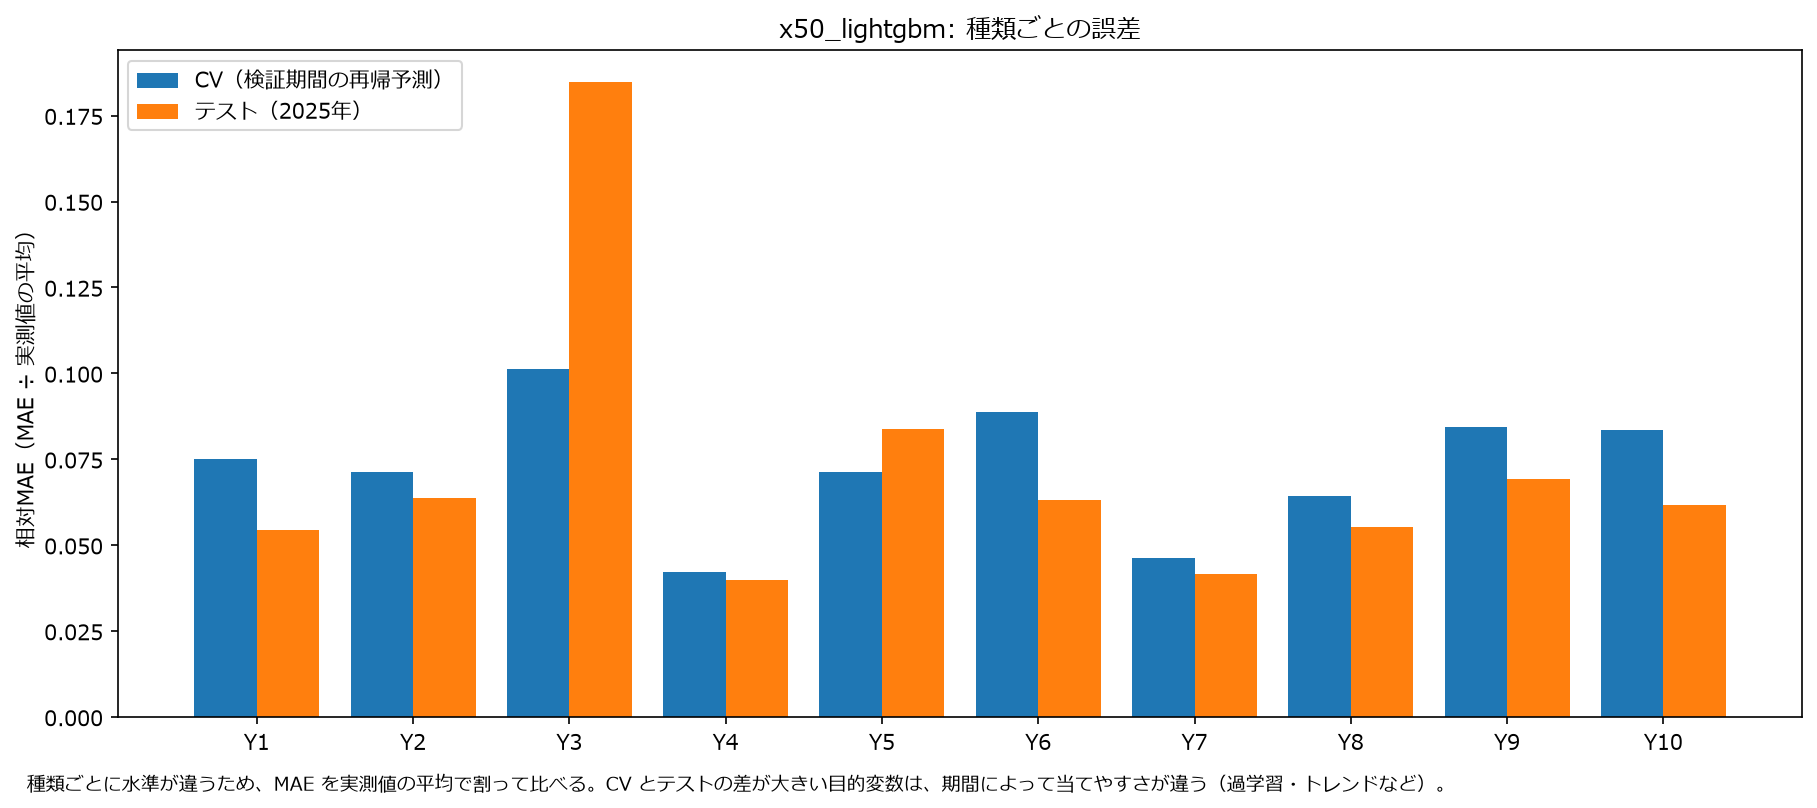

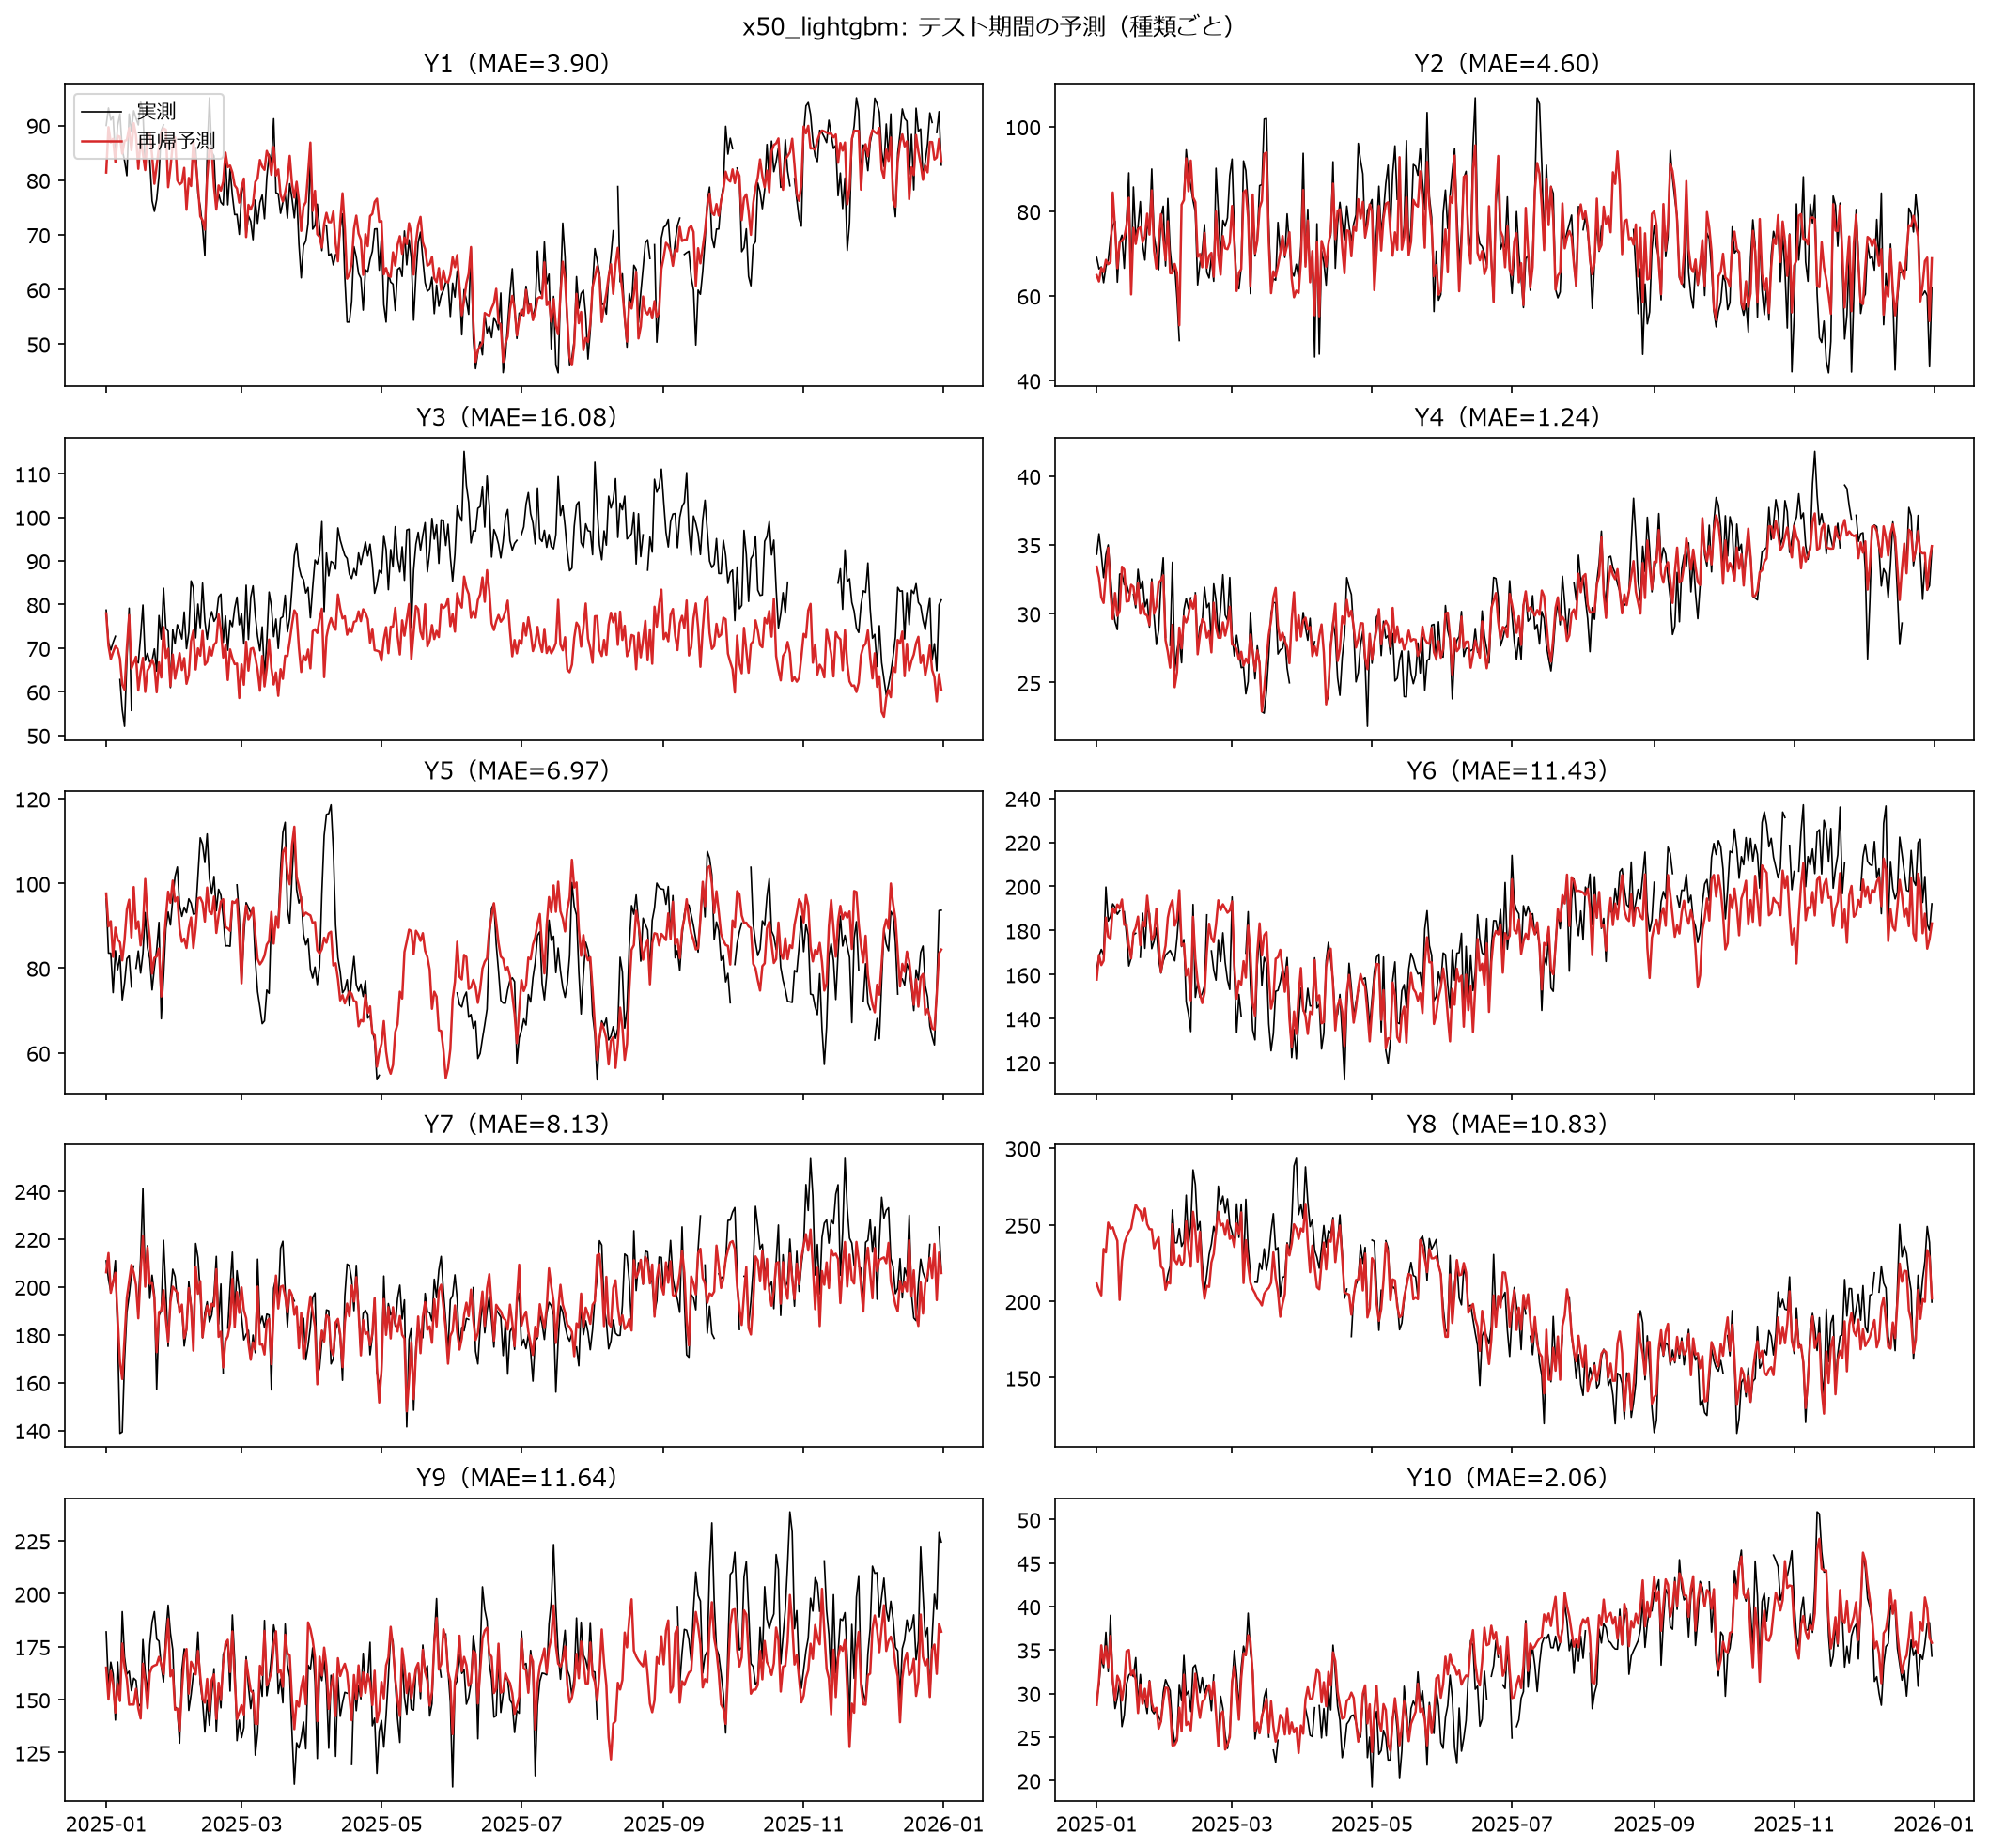

In [14]:
figures = summary_dir / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "test_overview.png"), width=1000))

## 4. SHAP によるモデル解釈（全種類）

種類ごとの SHAP 重要度（平均 |SHAP 値|）を、種類ごとに合計1の割合にして並べる。
各種類自身のラグ・移動平均・前日比は「自身_lag_1」などとして表示する。どの説明変数がどの種類に効いているかを比べられる。

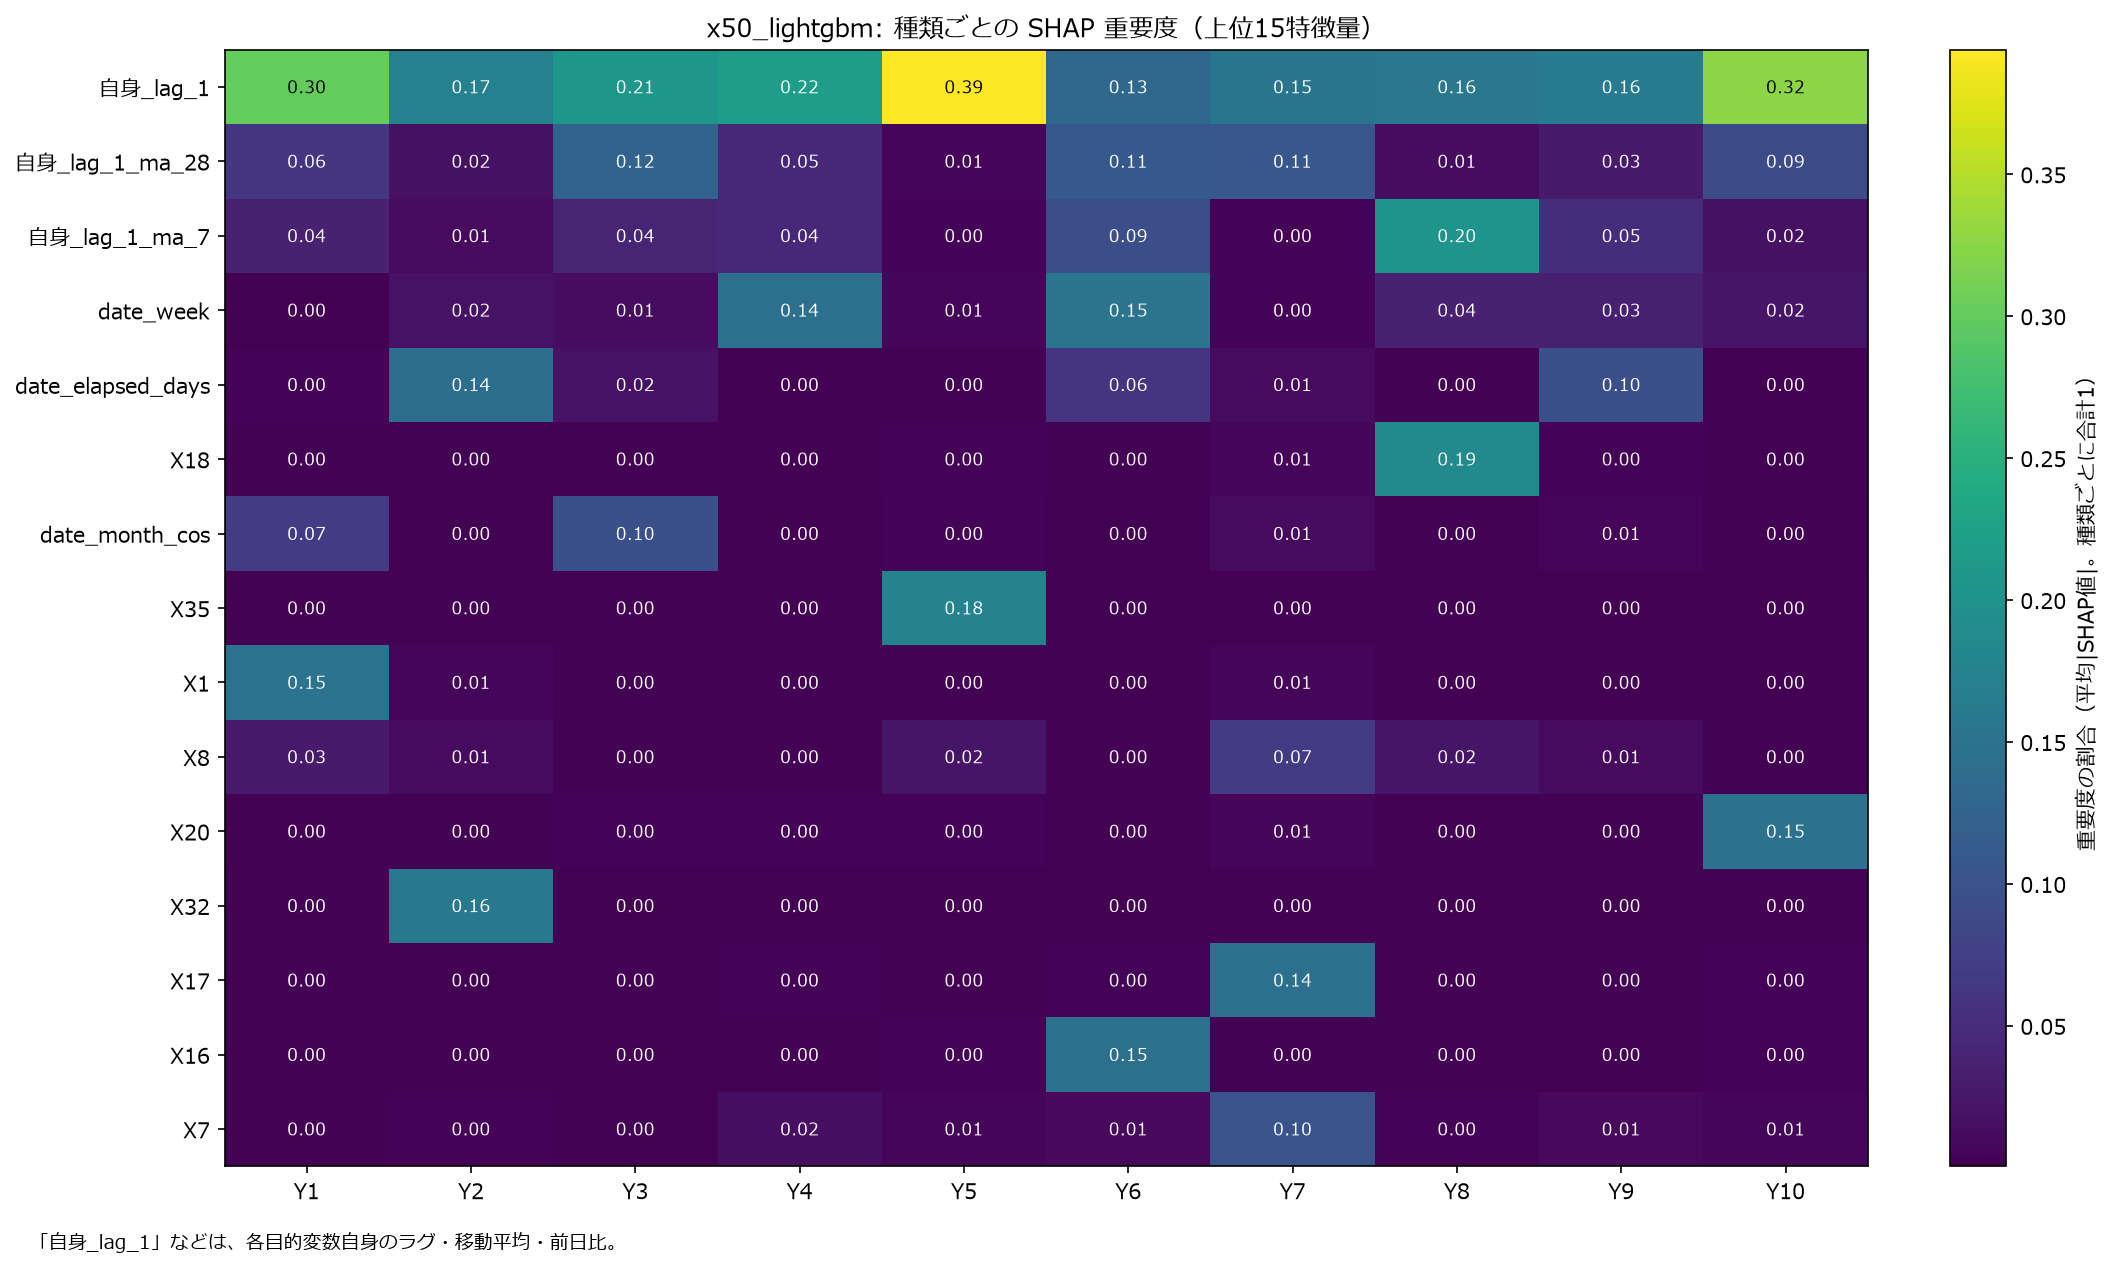

In [15]:
display(Image(filename=str(figures / "shap_overview.png"), width=800))

## 5. 1つの種類の詳細（`DETAIL_TARGET`）

### 学習結果

- **学習期間の実測値と検証期間の再帰予測:** 各 fold の検証期間（網掛け）を、実測値を使わずに予測した結果。
- **予測ステップ別の MAE:** 検証期間の何日目の予測かごとの MAE。先の日ほど誤差が積み重なる。
- **学習の推移:** 木の本数ごとの学習・検証の損失（対数の尺度）。

Y1: outputs/experiments/x50_lightgbm_Y1/20261025_232944_042839


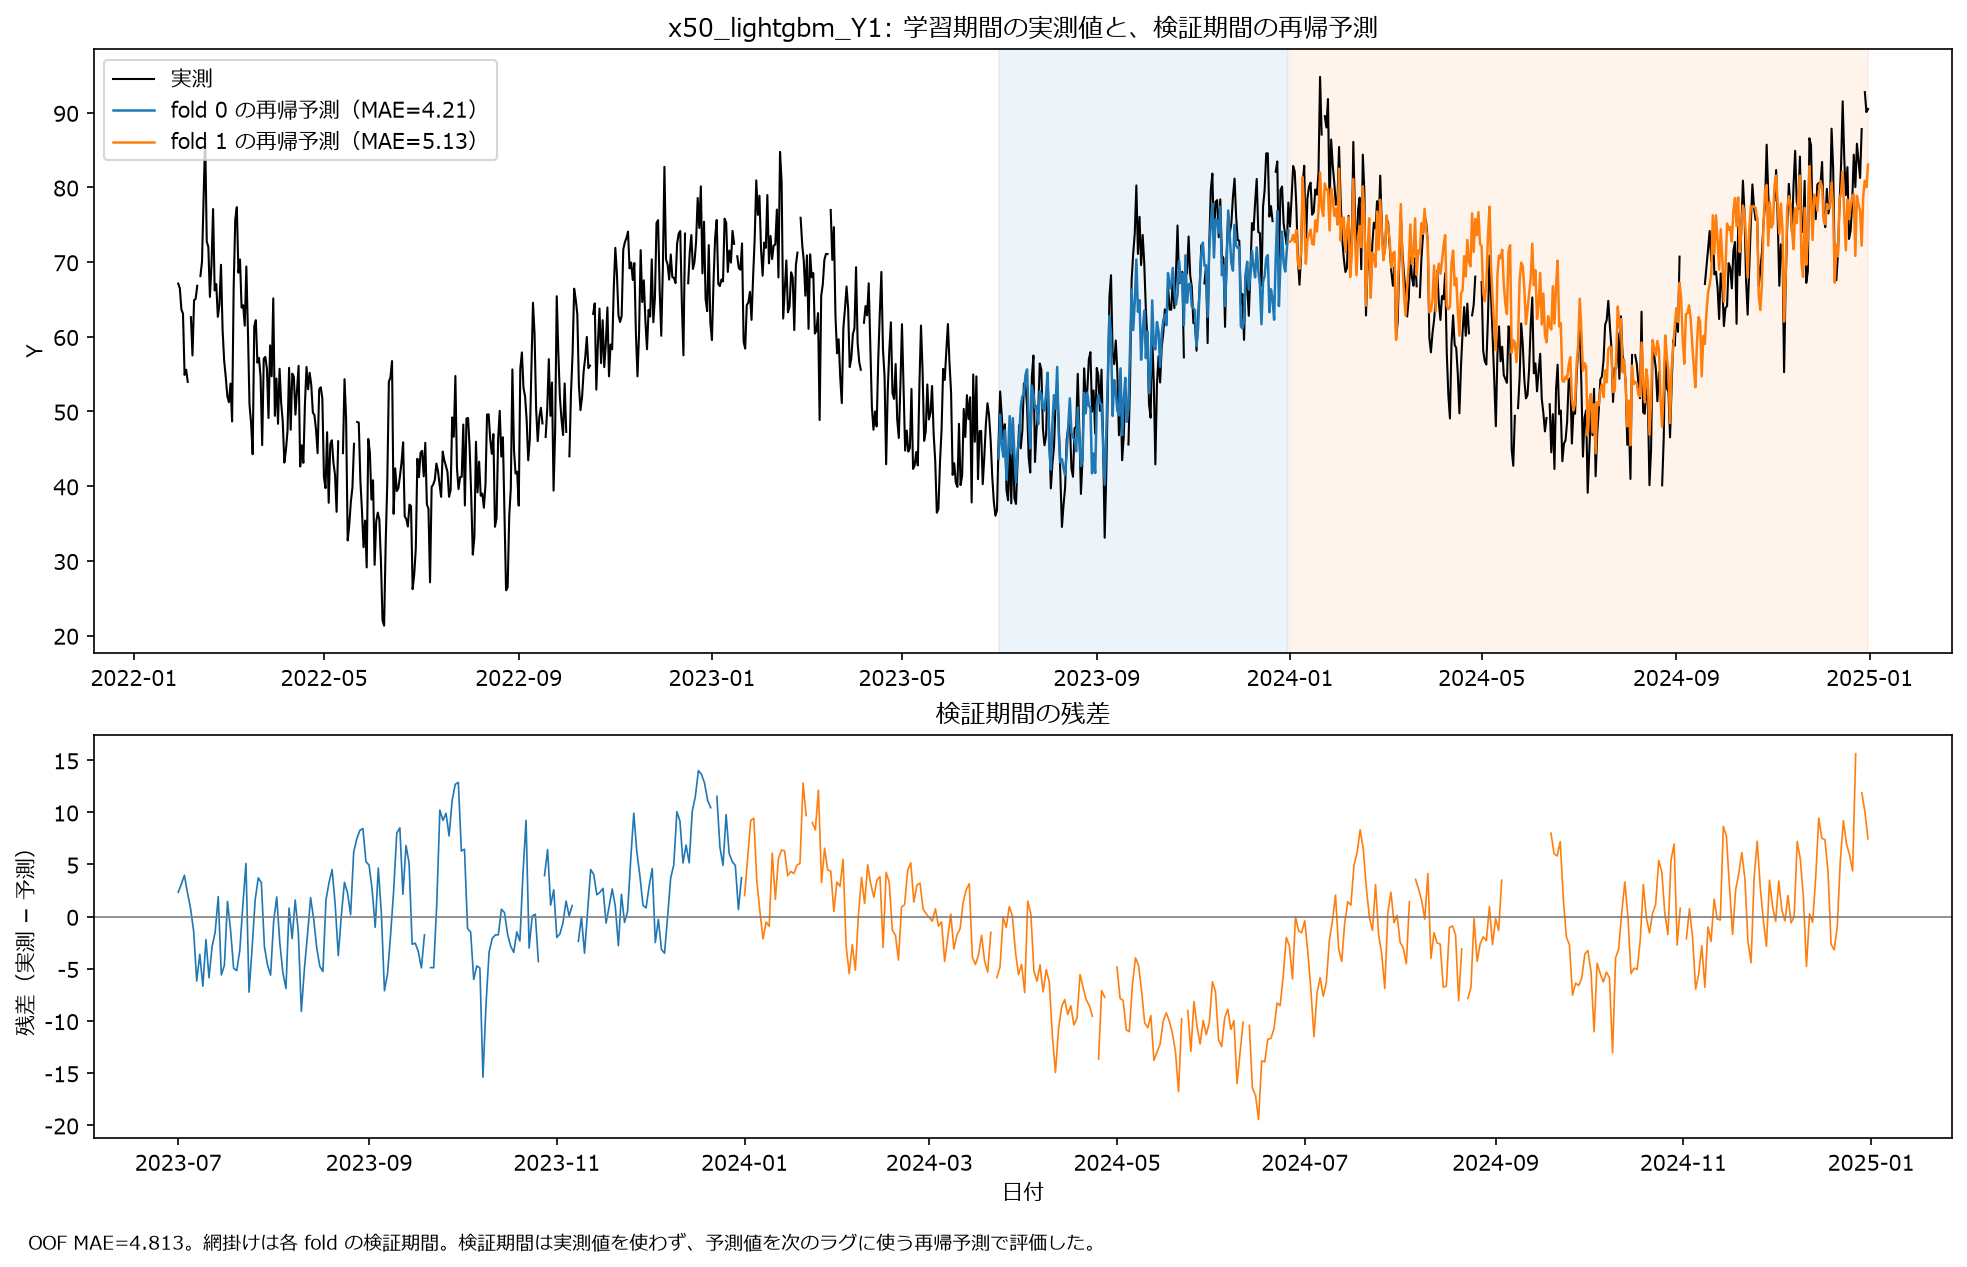

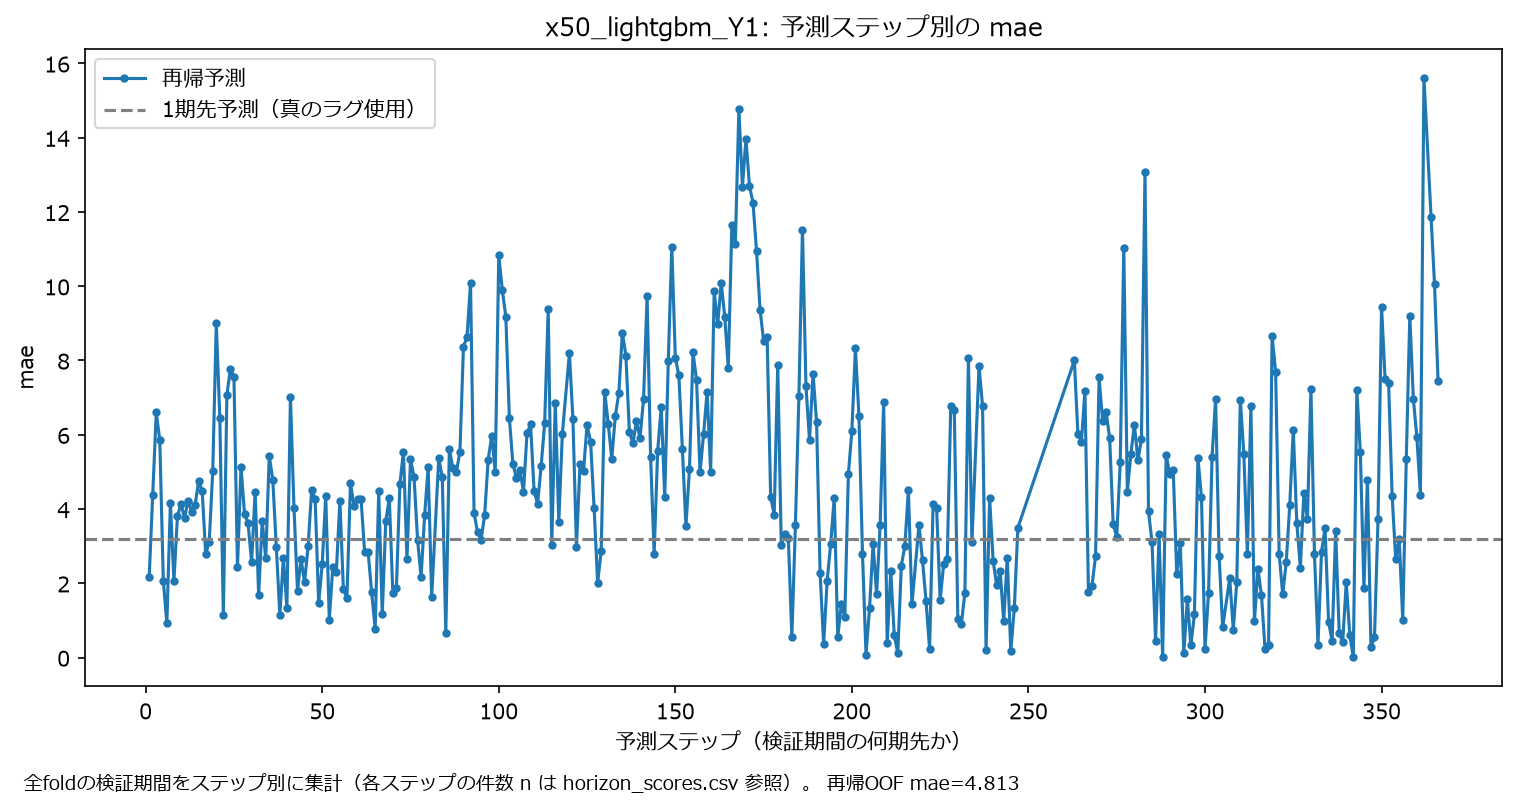

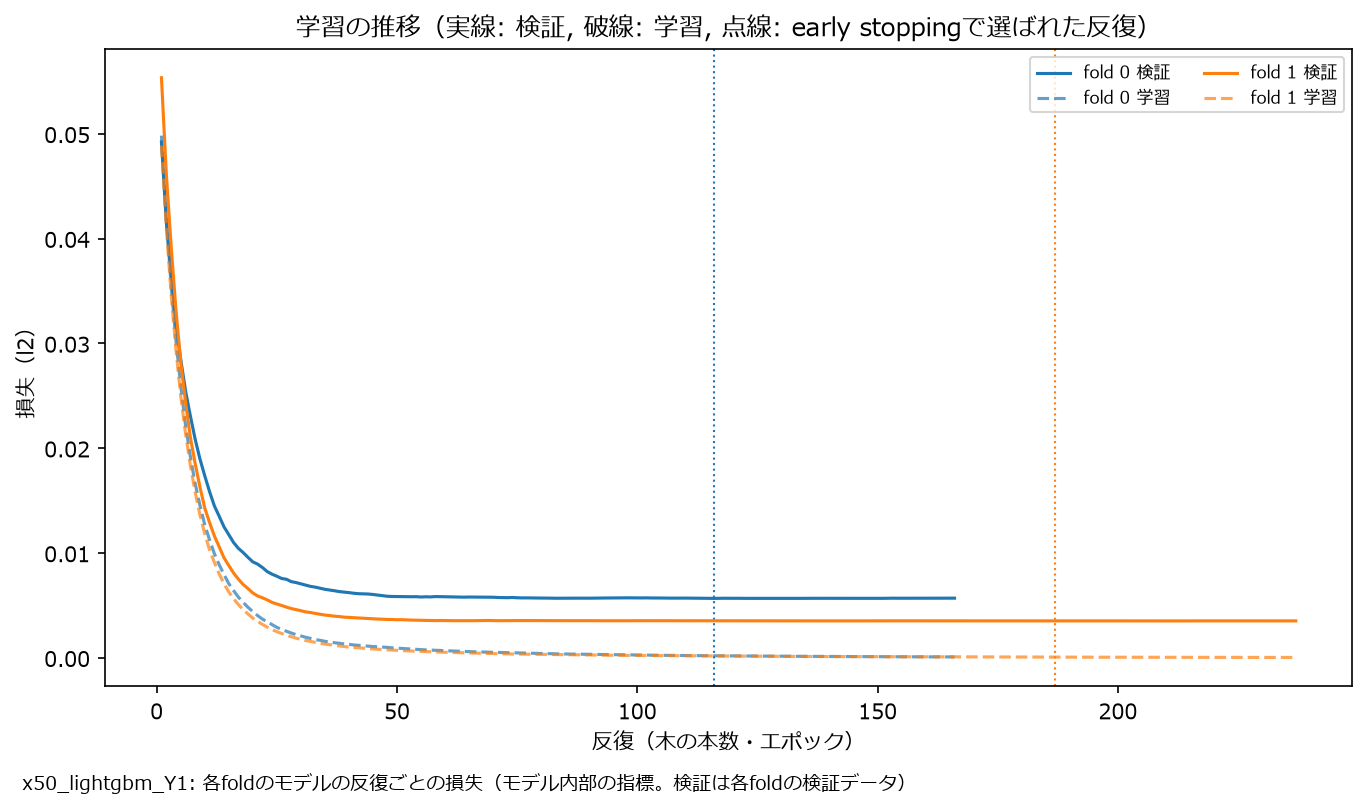

In [16]:
detail = next(run for run in runs if run.category == DETAIL_TARGET)
out = detail.result.output_dir
print(f"{DETAIL_TARGET}: {shown(out)}")
display(Image(filename=str(out / "figures" / "training_result.png"), width=1000))
display(Image(filename=str(out / "horizon_error.png"), width=800))
display(Image(filename=str(out / "evaluation" / "training_history.png"), width=800))

検証期間の残差の診断（`modeling.evaluation` が作る図）。残差に偏り・自己相関が残っていないかを見る。

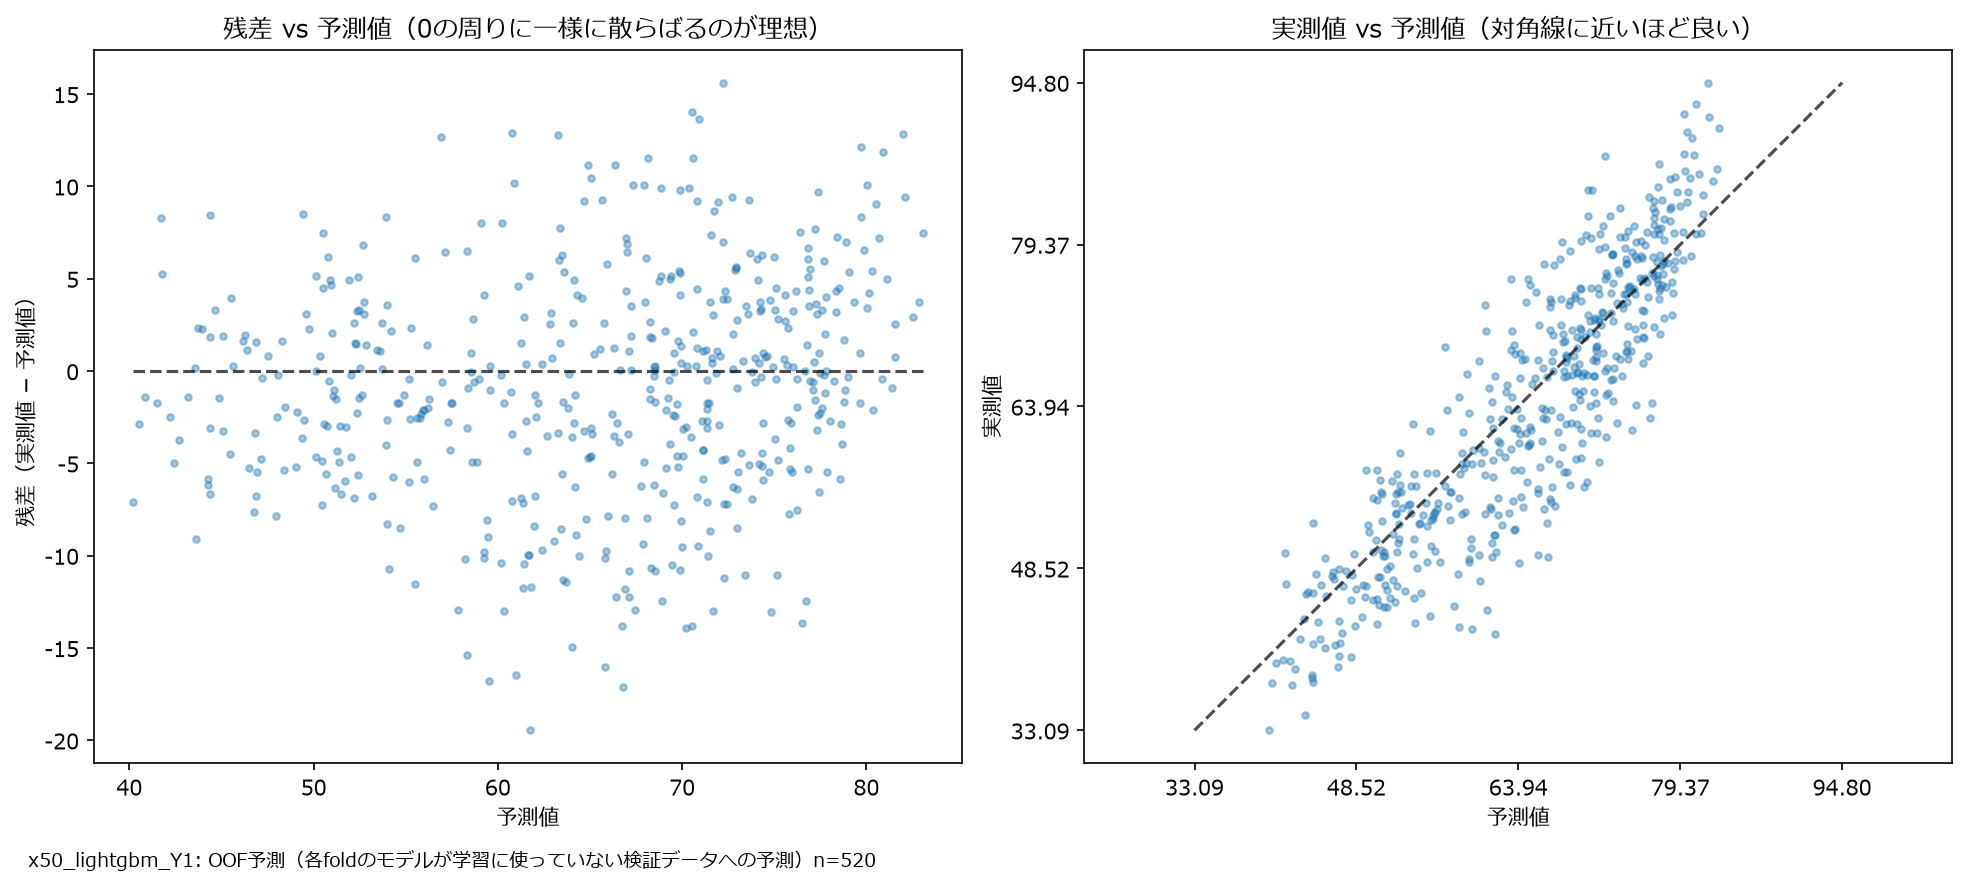

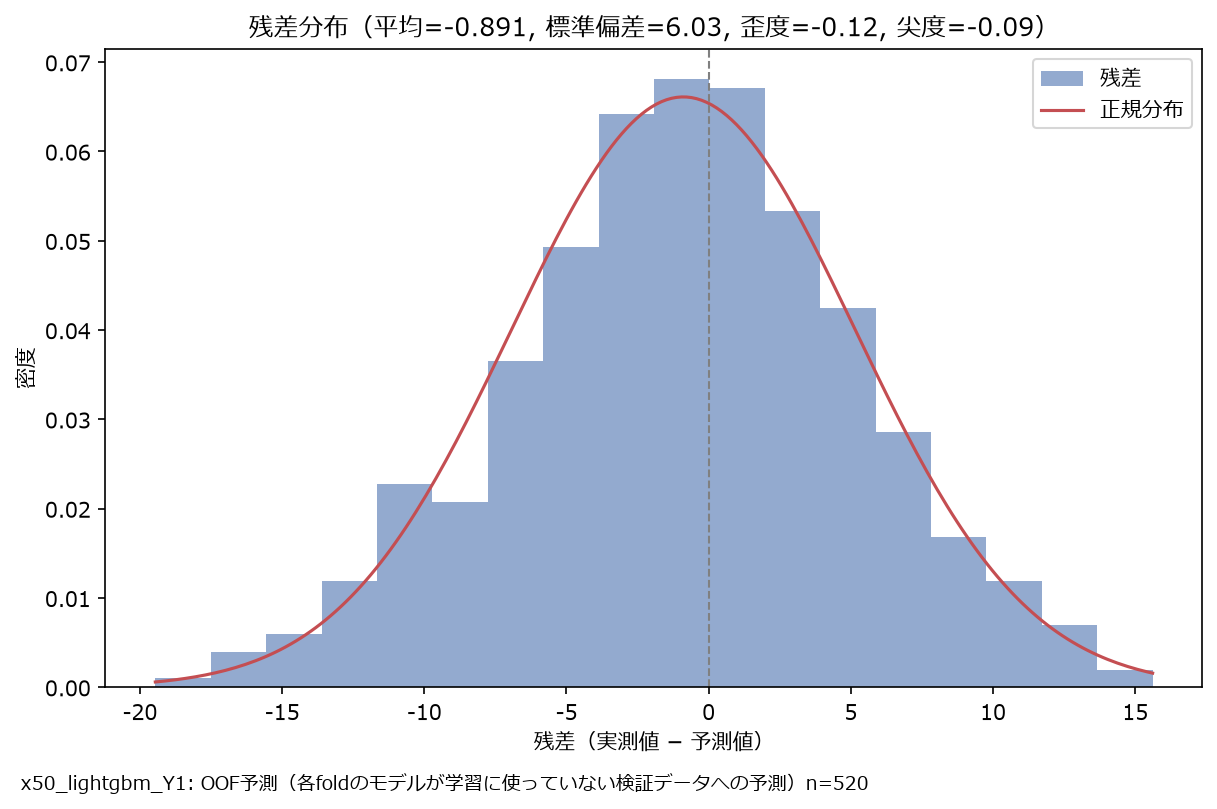

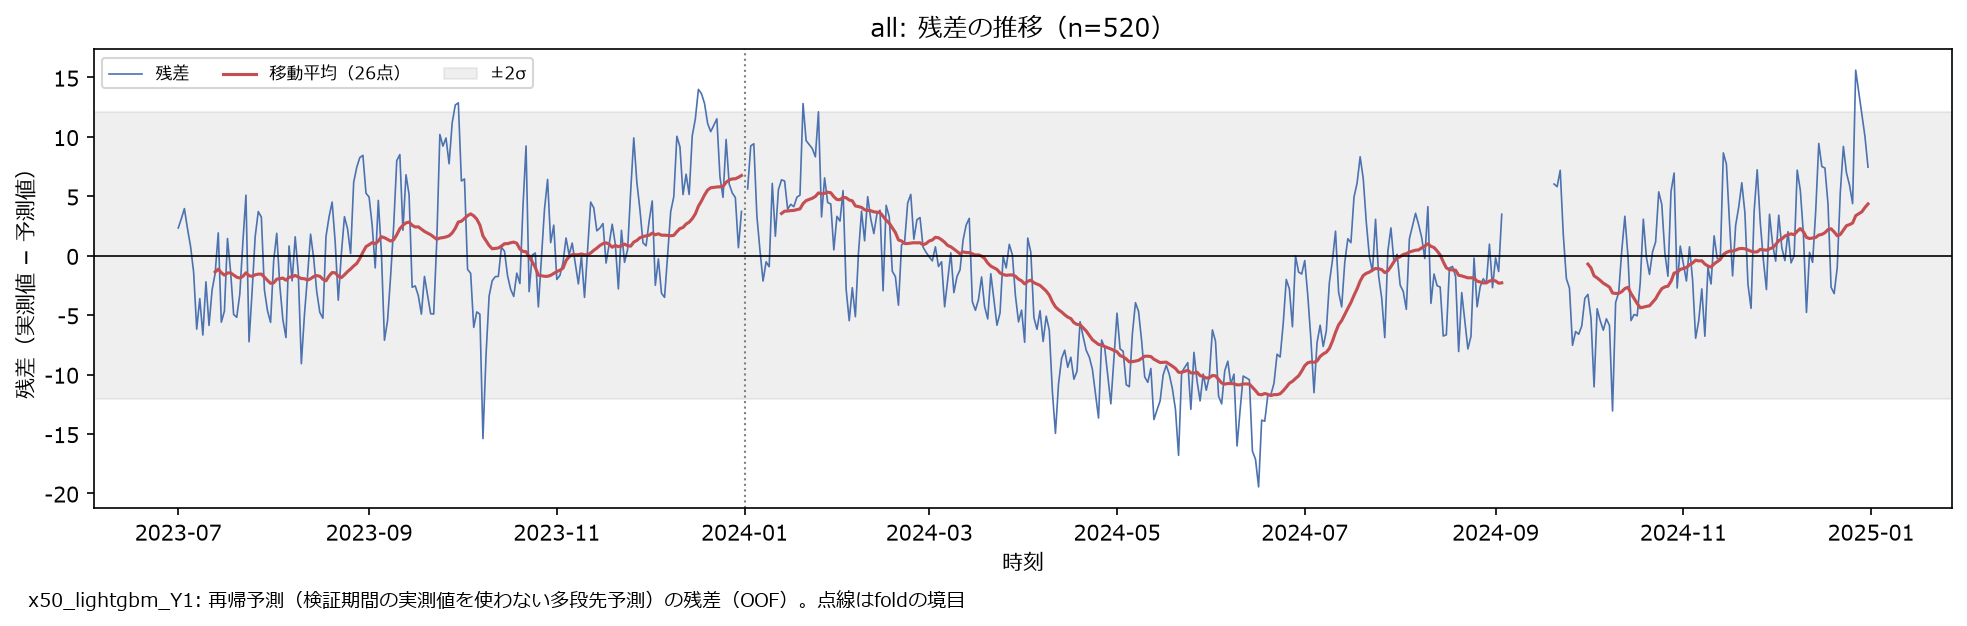

In [17]:
for name in ("residual_plot.png", "residual_distribution.png", "residual_timeseries.png"):
    display(Image(filename=str(out / "evaluation" / name), width=850))

### テスト結果

テスト期間（2025年）の再帰予測と実測値、予測と実測の散布図、月別の MAE。

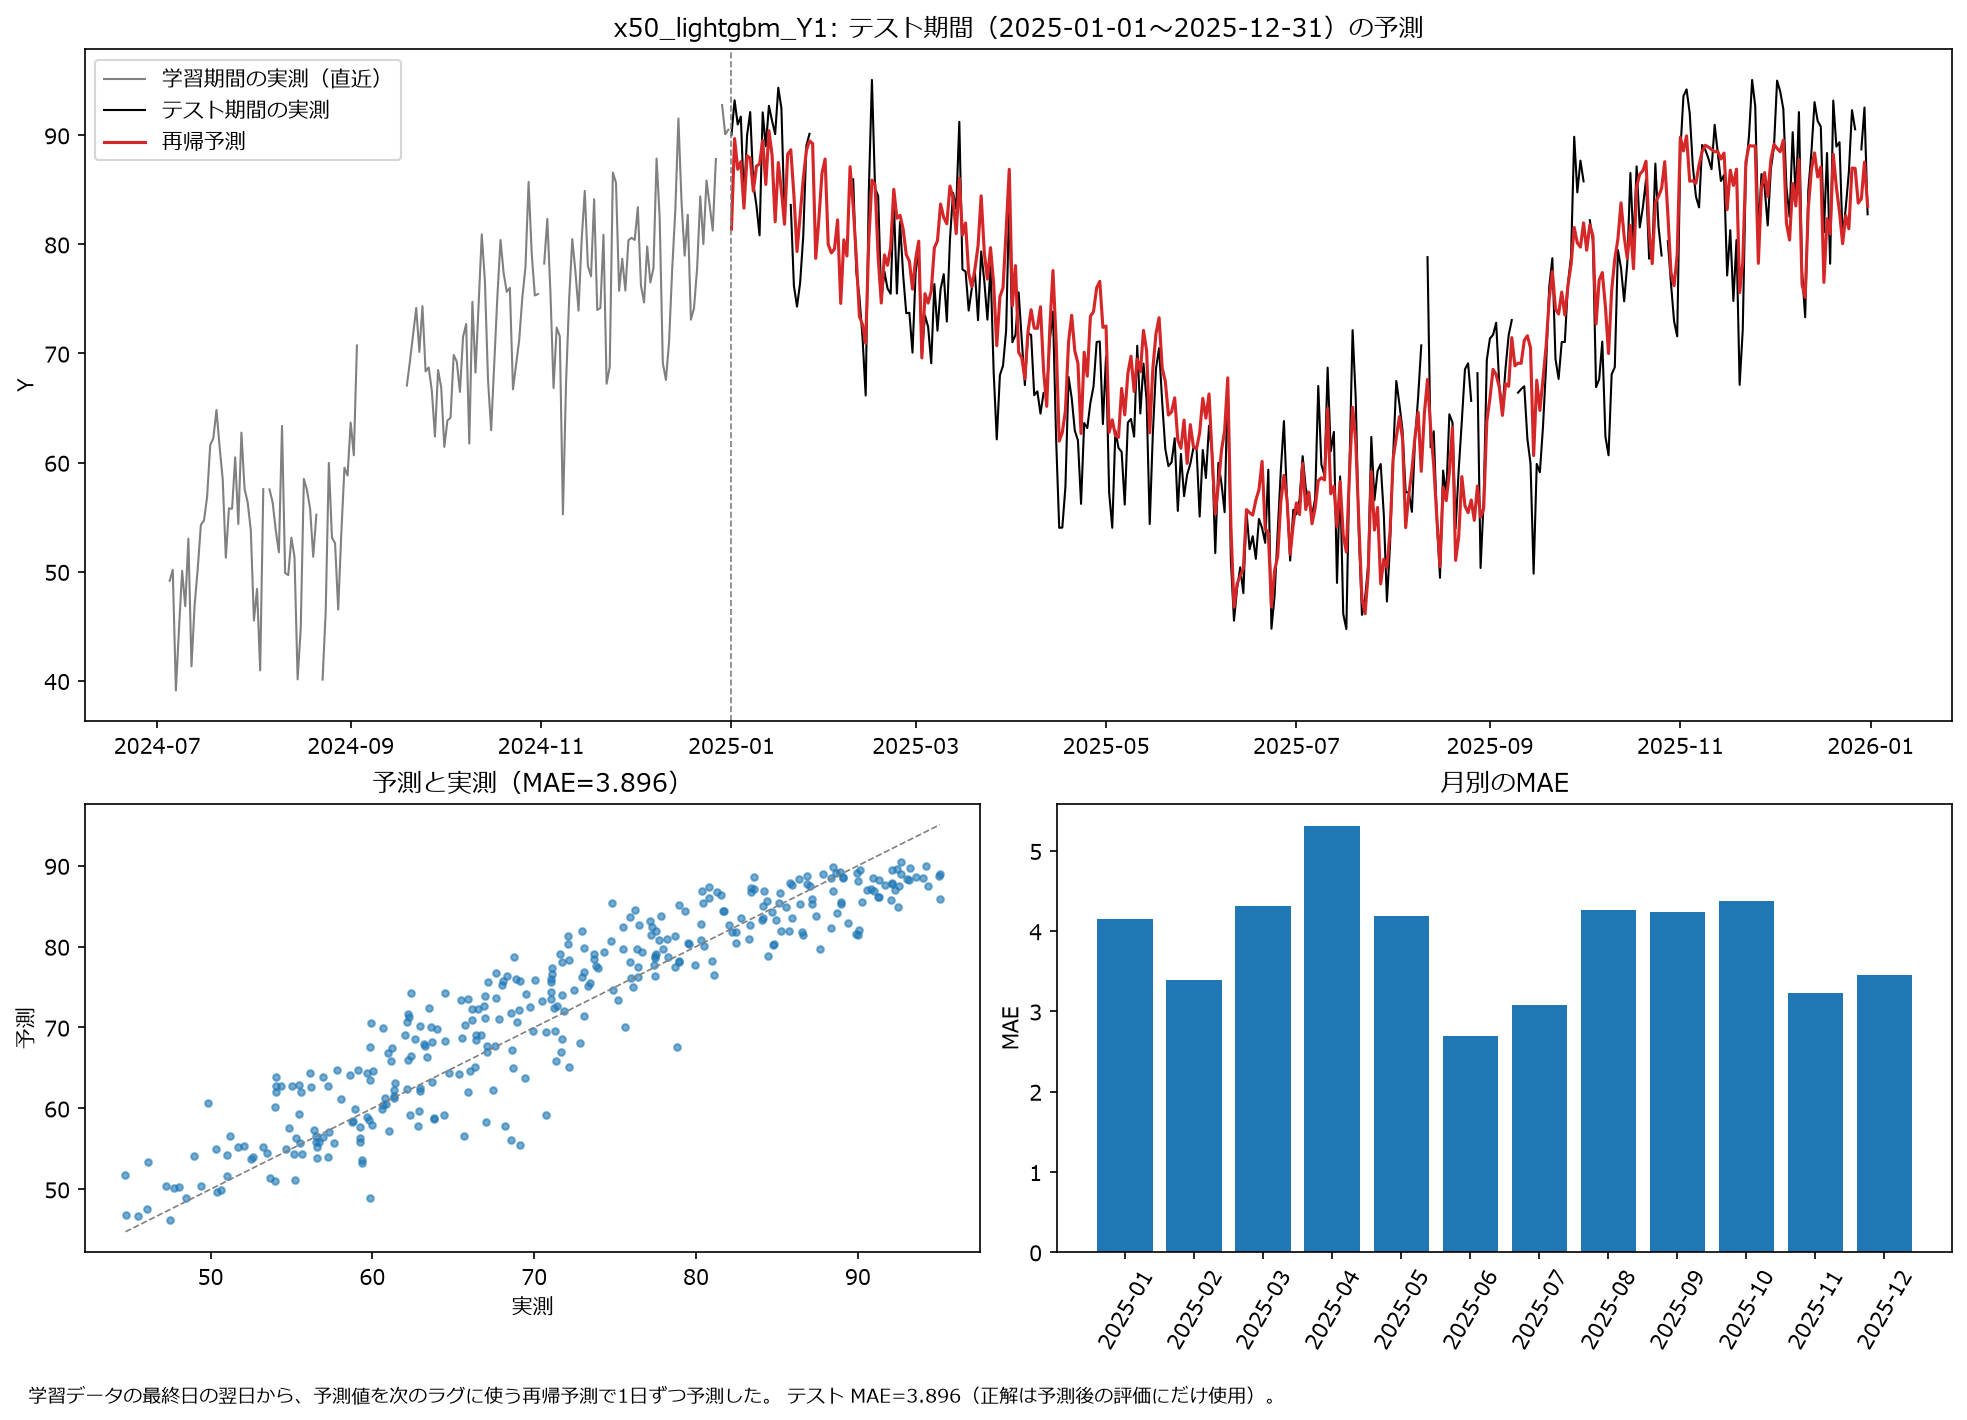

In [18]:
display(Image(filename=str(out / "figures" / "test_result.png"), width=1000))

### SHAP によるモデル解釈

各 fold のモデルを、その検証期間のデータで説明した SHAP 値（OOF SHAP）。モデルは目的変数の対数を予測するため、
SHAP 値も対数の尺度（例: 0.01 は予測値を約1%押し上げる）。

- **重要度:** 平均 |SHAP 値| の大きい特徴量ほど予測への影響が大きい。
- **beeswarm:** 各点が1日。色は特徴量の値（赤=大きい）、横軸は予測への寄与。
- **効きの向き:** 特徴量の値が大きいほど予測を押し上げる（赤）か、押し下げる（青）か。
- **依存関係:** 上位の特徴量の値と SHAP 値の関係。

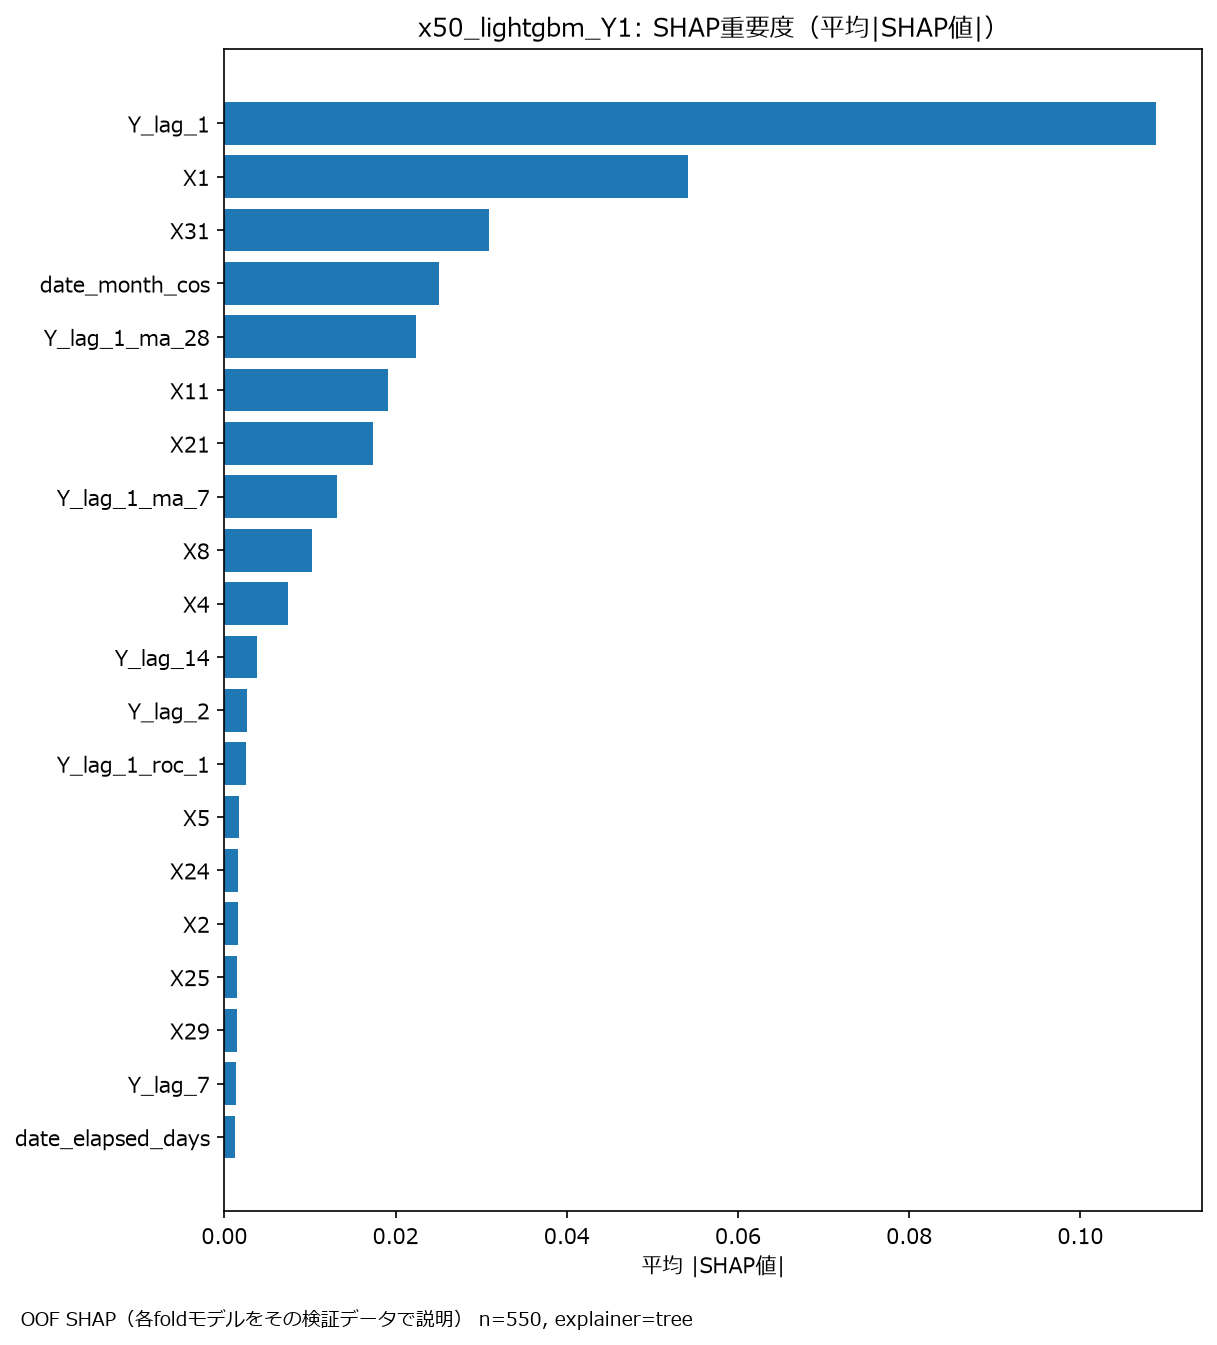

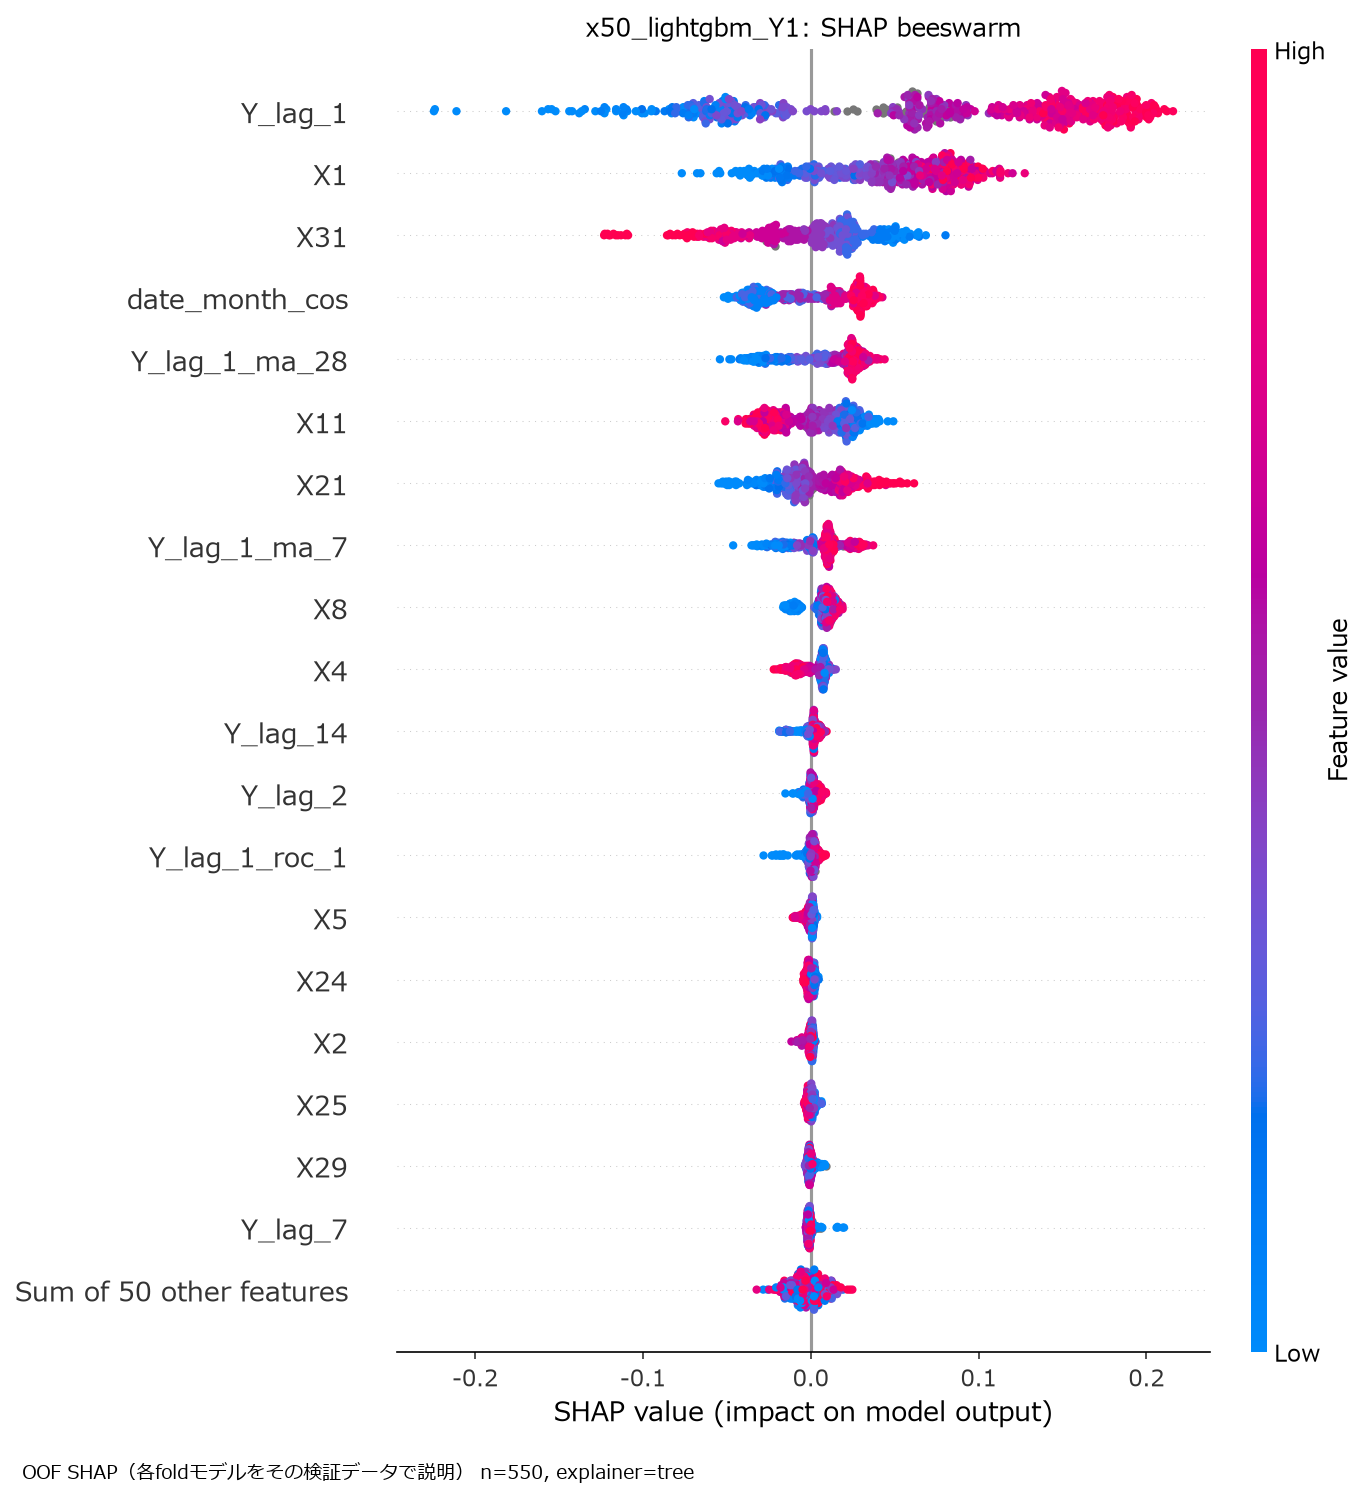

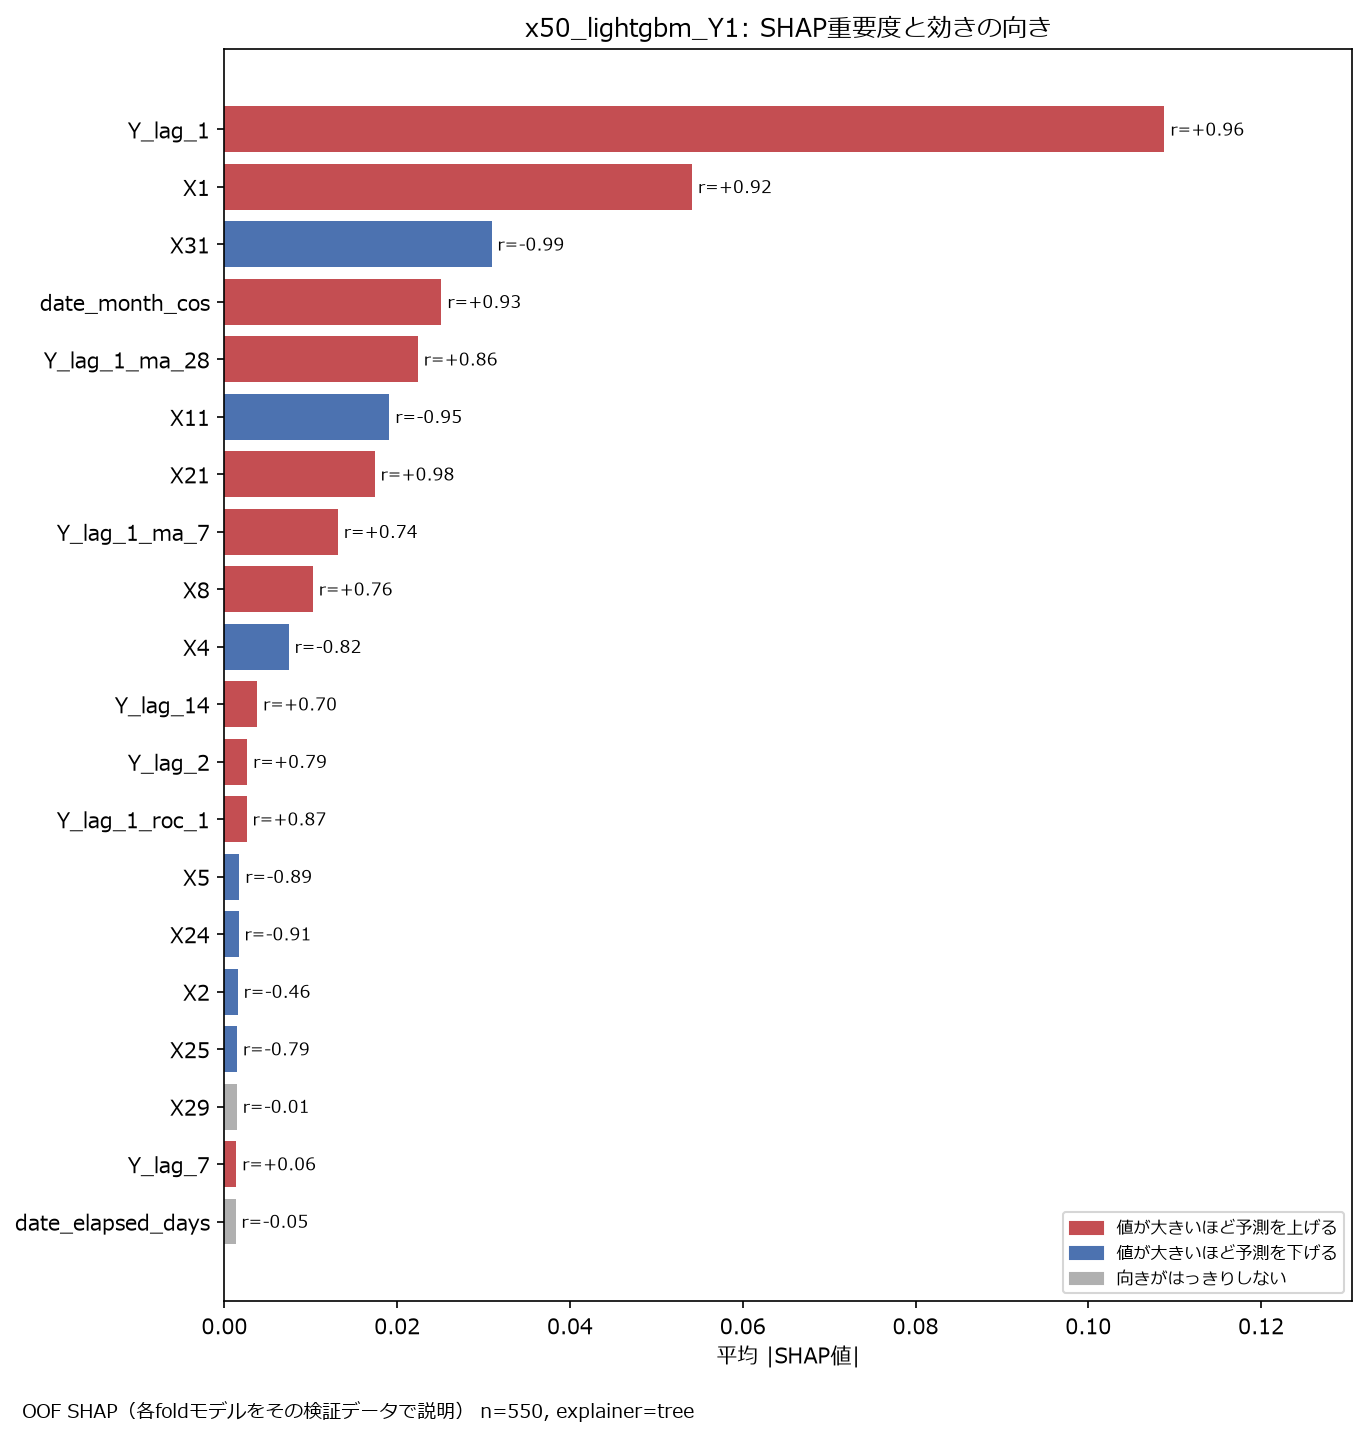

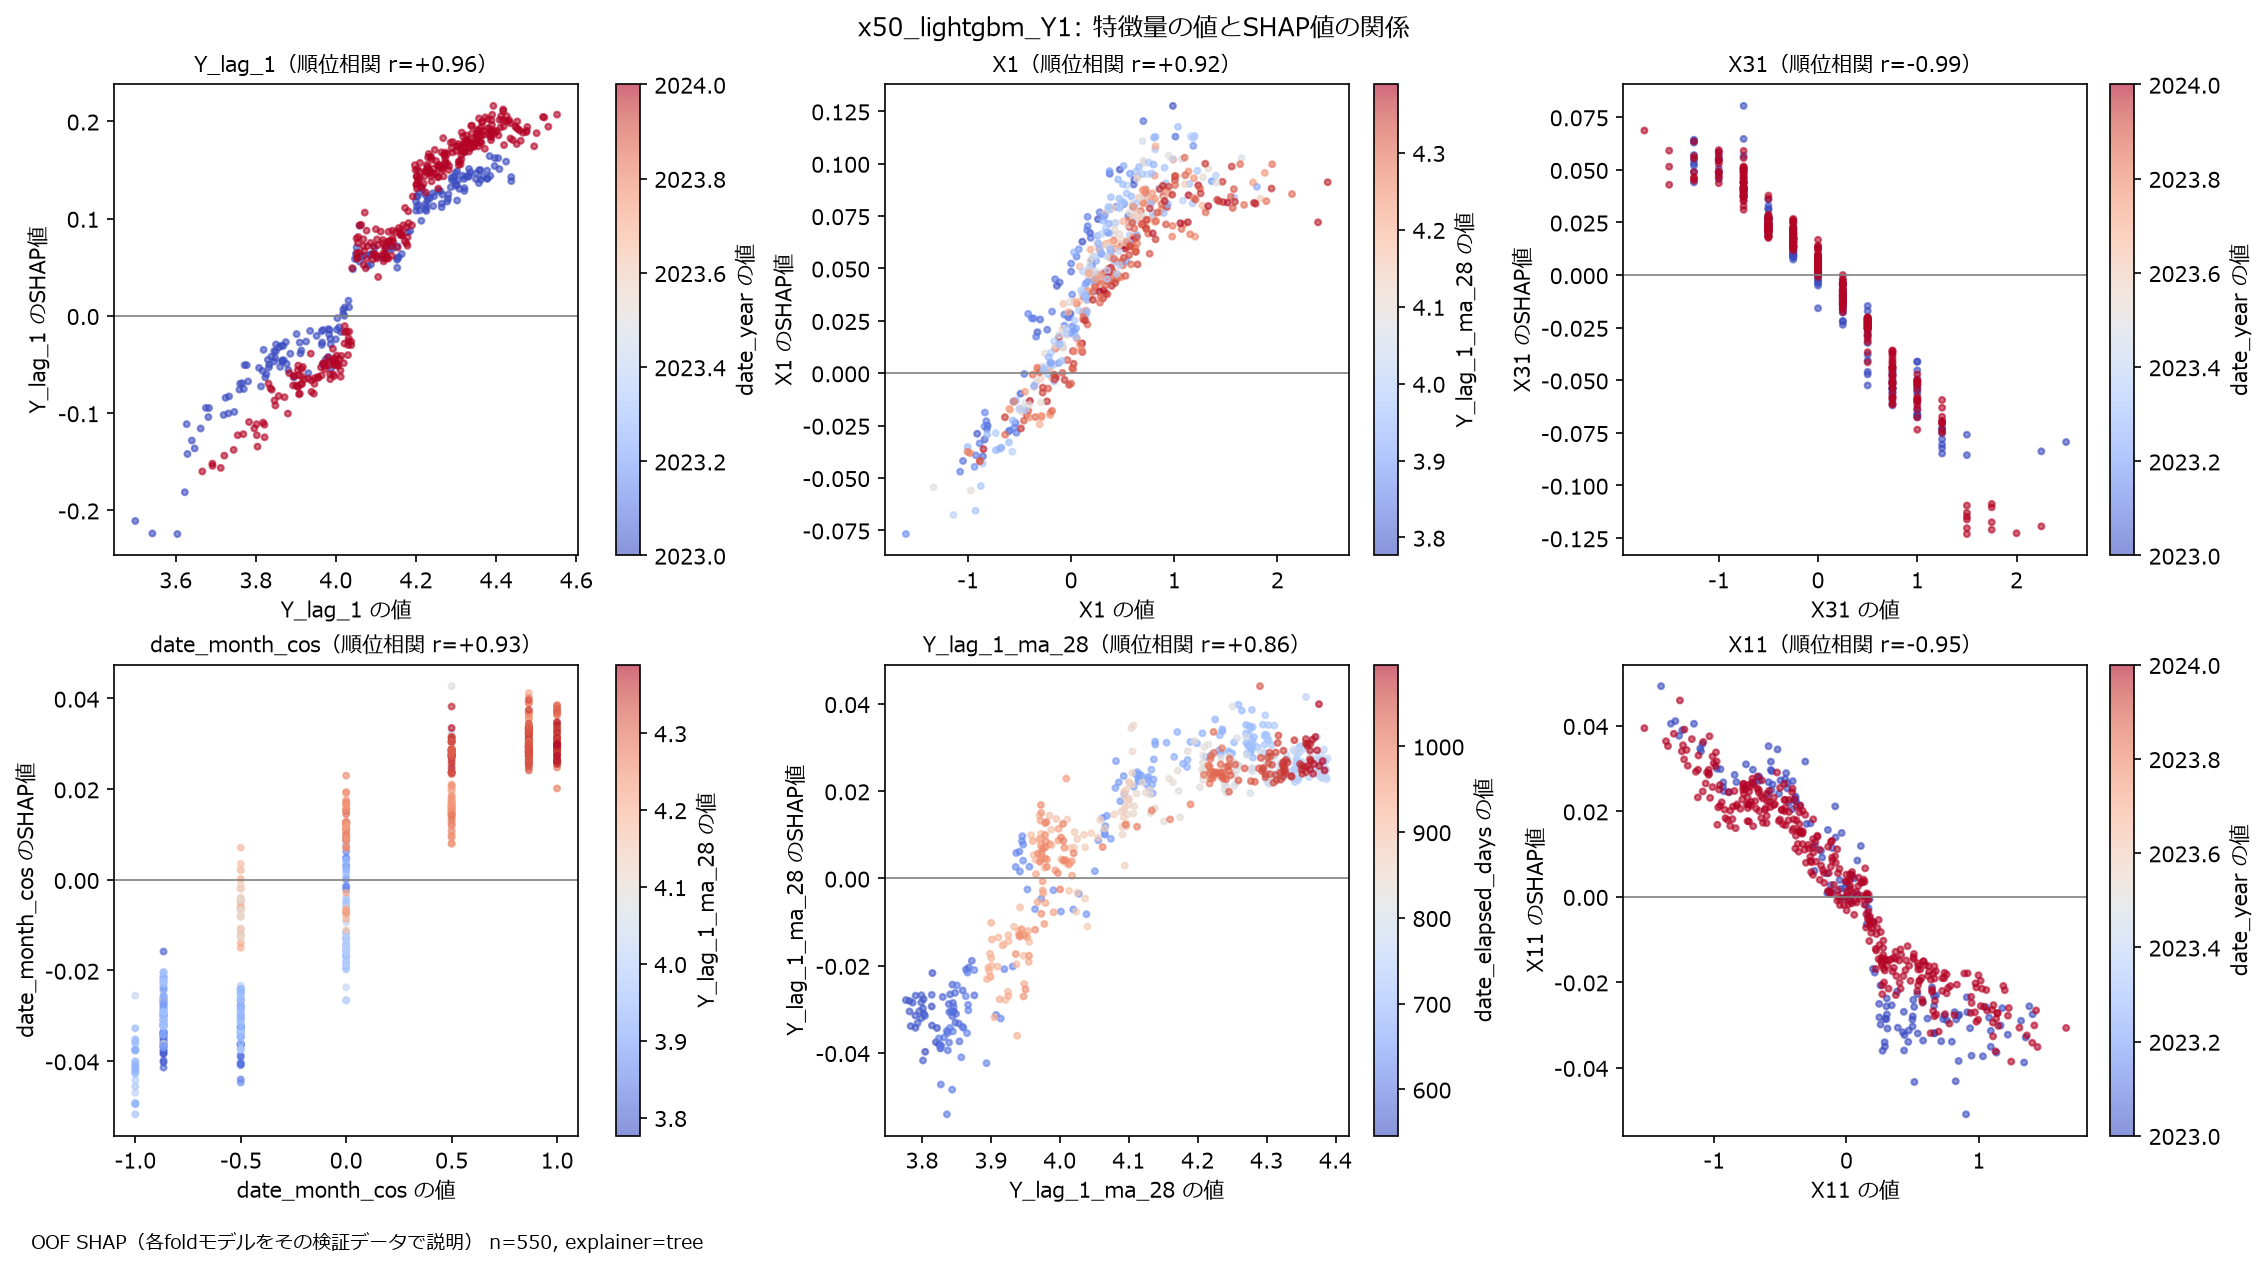

In [19]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(shap_dir / "shap_correlation_bar.png"), width=800))
display(Image(filename=str(shap_dir / "shap_dependence.png"), width=1000))

## まとめ

- 目的変数の種類（`Y_cat` = Y1〜Y10）ごとに、その種類の行だけで選んだモデルを学習し、2025年を再帰予測した。
  目的変数のラグ・移動平均は、検証・テスト期間では予測値から作り直している。各モデルは自分自身のラグだけを使い、
  他の種類の値は使わない。
- CV は本番と同じ条件（検証期間の実測値を使わない再帰予測）で評価しているため、CV の MAE とテストの MAE を比べて、
  過学習や期間による違いを確認できる。
- ログはファイル（`outputs/logs/`、要約ディレクトリの `run.log`）と MLflow（種類ごとの run と要約の run。
  同じ `batch` タグで結び付く）に残している。

**注意点**

- 種類ごとに水準が違うため、種類をまたいで比べるときは相対MAE を使う。
- トレンドのある種類（ダミーでは Y3・Y6・Y9）は、テスト期間に学習範囲より高い水準になる。木のモデルは学習範囲の
  外へ外挿できないため、テストの誤差が CV より大きくなりやすい（差分の変換などを検討する）。
- 目的変数が欠損の日は、CV・テストの評価から除いている（評価した日数はログ・`test_scores.csv` の `n`）。
  長い連続した欠損の直後は、ラグ・移動平均が欠損または少ない観測値から作られるため、予測が不安定になりやすい。
- SHAP は検証期間（OOF）での説明。テスト期間のモデル（学習データ全体で学習し直したもの）とは、学習に使った期間が違う。